# PLACE: concept extraction demo

Demo of PLACE (Patch-Level Agnostic Concept Extraction) on one ImageNet class, *church* (class 497).
PLACE factorizes the patch tokens of a frozen ViT into a bank of concepts, and returns a heatmap for
each concept on each image.

The notebook runs four configurations, each extracting 25 concepts from the patch tokens of block 9:

| Section | Backbone | Method | Classifier used |
|---------|----------|--------|-----------------|
| 1a | ViT-B/16 (supervised, ImageNet) | PLACE (+KL) | yes, in the loss |
| 1b | ViT-B/16 (supervised, ImageNet) | PLACE (+Gram) | only to filter the images |
| 2  | DINOv2 ViT-S/14 | PLACE (+Gram) | no |
| 3  | ViT-MAE ViT-B/16 | PLACE (+Gram) | no |

Method details and results: https://gabrieleonorato.com/PLACE

The task-agnostic experiments (one bank for several classes, 20 seeds) are in
`task_agnostic_experiments.ipynb`.

## Method overview

1. **Split the model.** The frozen ViT is split after block $\ell = 9$. The prefix $g_{\le \ell}$
   maps an image to a grid of patch tokens; the suffix $g_{>\ell}$ (remaining blocks and head) is
   only used by the +KL variant.
2. **Token grouping.** Patch tokens are averaged over non-overlapping 2×2 blocks (for ViT-B/16, the
   14×14 grid becomes 7×7, i.e. 49 tokens per image).
3. **Semi-NMF.** The tokens of all images are stacked into a matrix $A$ (one row per token) and
   factorized as $A \approx UW^\top$, with $U \ge 0$. Each column of $W$ is a concept, and $U$ gives
   the amount of each concept at each token. $W$ is unconstrained in sign because transformer
   activations are mixed-sign.
4. **Loss.**

   $$\mathcal{L} = \tfrac{1}{2}\|A - \hat A\|_F^2 + \lambda\,\frac{\|AA^\top - \hat A\hat A^\top\|_F^2}{\|AA^\top\|_F^2}, \qquad \hat A = UW^\top$$

   The first term is the reconstruction error, the second the normalized Gram-matrix alignment.
   Together they upper-bound the KL divergence of any linear classifier on the model (Proposition 1
   in the paper), so no labels or classifier are needed. In the code the reconstruction term is the
   mean squared error, and the Gram term is computed on a random subset of 2,048 tokens per step.
5. **Heatmaps.** Each row of $U$ corresponds to one patch of one image, so a concept's column of
   $U$ is reshaped onto the token grid and upsampled (bicubic) to the image size.

Optimization: AdamW on $U$ and $W$; $U$ initialized with NNDSVD (on 80% of the rows) and
$W = U^\dagger A$; negative entries of $U$ clamped to zero after each step; gradient clipping;
small L1 penalty on $U$ and L2 penalty on $W$; early stopping when the change in loss falls below
`EPSILON`.

## Setup

Skip the next cell if the environment was installed with `uv sync` or `requirements.txt`.

In [1]:
# Uncomment if needed:
# %pip install torch torchvision timm tqdm numpy matplotlib Pillow scipy -q

In [2]:
import math
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torch.linalg import svd
import timm
import matplotlib.pyplot as plt
from tqdm import tqdm
from math import ceil

%matplotlib inline
warnings.filterwarnings('ignore')
print(f'PyTorch {torch.__version__} | CUDA: {torch.cuda.is_available()}')

.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.8.0+cu128 | CUDA: True


### Configuration

Defaults follow the hyperparameters in the paper (Table 6).

- `DATA_PATH`, `TARGET_CLASS`: church images and their ImageNet class index (497).
- `SPLIT_LAYER`, `VFM_LAYER`: block whose patch tokens are used (0-indexed). For ViT-B/16, blocks 10
  and 11 and the head form the suffix used by the KL term.
- `GROUP_SIZE`: token grouping factor (2 = 2×2 blocks).
- `VFM_N_IMAGES`: number of images used in sections 2 and 3.
- `RANK`: number of concepts.
- `STEPS`, `LR`, `EPSILON`: maximum optimization steps, AdamW learning rate, early-stopping tolerance.
- `LAMBDA_VAL`: weight $\lambda$ of the Gram or KL term.
- `L1_U`, `L2_W`, `NNDSVD`: regularization on $U$ and $W$, and percentage of rows used for the NNDSVD
  initialization.
- `BATCH_SIZE`: batch size for preprocessing, filtering and token extraction. `NMF_BATCH`: batch size
  for the logit computations of the +KL bank (reference logits and concept importance).
- `TOP_K`: images shown per concept.
- `COMPUTE_STABILITY`: refit each method five times at the end to measure W-Stab (slow).

To run on a CPU, set `STEPS = 3000` and `VFM_N_IMAGES = 50`.

In [3]:
# ── Configuration ─────────────────────────────────────────────────────────────
DATA_PATH    = './data/church_images.npz'
TARGET_CLASS = 497        # ImageNet-1k: church
DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'

SPLIT_LAYER  = 9          # ViT blocks 0..9 → g;  blocks 10..11 → h
GROUP_SIZE   = 2          # 2×2 spatial grouping
VFM_LAYER    = 9          # layer for DINOv2 / MAE extraction
VFM_N_IMAGES = 200        # images used for unsupervised VFM methods

RANK        = 25
STEPS       = 22_000
LR          = 5e-4
LAMBDA_VAL  = 1.0
EPSILON     = 1e-6
L1_U        = 1e-6
L2_W        = 1e-6
NNDSVD      = 80.0
BATCH_SIZE  = 64
NMF_BATCH   = 4

TOP_K             = 5
COMPUTE_STABILITY = True  # run the stability check at the end (slow)

OUT_DIR = './output'
import os; os.makedirs(OUT_DIR, exist_ok=True)
print(f'Device: {DEVICE}')

Device: cuda


---

## Helper code

Class and function definitions; run these cells once.

- `ViTLayerSplit`: wraps a ViT with a classifier (timm, torchvision or torch hub).
  `extract_patch_tokens` returns the CLS token and the grouped patch tokens at `split_layer`;
  `classify_from_tokens` ungroups a set of tokens, runs the remaining blocks and the head, and returns
  the logits (used by the KL term).
- `PatchNMF`: PLACE for models with a classifier. `fit` runs the optimization with the MSE term plus,
  optionally, the KL term (32 random images per step) or the Gram term. Also provides image
  filtering, concept importance and stability.
- `load_vfm`, `VFMFeatureExtractor`: token extraction for foundation models without a classifier.
- `UnsupervisedPatchNMF`: `PatchNMF` without the classifier-dependent parts.
- `compute_gini_index`: C-Gini, the Gini coefficient of the concept-importance vector (higher =
  sparser). Importance is the mean absolute change of the target logit when the concept is zeroed
  out for the +KL bank, and $\|u_j\|^2\,\|w_j\|^2$ otherwise.
- `show_concept_heatmaps`: for each concept, overlays its upsampled coefficient map on the `TOP_K`
  images where it is most active.

In [4]:
# ── ViTLayerSplit ──────────────────────────────────────────────────────────────

class ViTLayerSplit(nn.Module):
    """
    Splits a timm, torchvision, or torch.hub ViT into feature extractor (g)
    and head (h).

    Supported backbones:
        - timm ViT (has ``blocks`` + ``_pos_embed`` method)
        - torchvision ViT (has ``encoder.layers``)
        - torch.hub DINOv1/v2/v3 (has ``blocks`` + ``prepare_tokens*`` method)

    Parameters
    ----------
    head : nn.Module, optional
        External classification head (e.g. a linear probe).  When provided it
        is used in ``classify_from_tokens`` instead of the model's own head.
        Required for hub VFMs which have no built-in classifier.
    """
    def __init__(self, vit_model, split_layer=11, group_size=1, head=None,
                 lc_layers=None):
        """
        Parameters
        ----------
        lc_layers : int or None
            Set to the number of last blocks used by DINOv2 _lc heads (1 or 4).
            When set, classify_from_tokens builds the multi-block concatenated
            input that DINOv2's linear heads expect:
              cat(CLS_last_n_blocks..., avg_patches_from_last_block)
            Leave None for simple single-CLS-token heads.
        """
        super().__init__()
        self.vit = vit_model
        self.split_layer = split_layer
        self.head = head  # optional external classifier (e.g. linear probe)
        self._lc_layers = lc_layers  # DINOv2 _lc multi-block head config

        # ── Architecture detection ──────────────────────────────────────────
        # timm: has both `blocks` and `_pos_embed` (a method)
        # torchvision: has `encoder.layers`
        # hub (DINOv1/v2/v3): has `blocks` and `prepare_tokens*`, no `_pos_embed`
        self.is_timm = hasattr(vit_model, 'blocks') and hasattr(vit_model, '_pos_embed')
        self.is_torchvision = not self.is_timm and hasattr(vit_model, 'encoder') and hasattr(vit_model.encoder, 'layers')
        self.is_hub = not self.is_timm and not self.is_torchvision and hasattr(vit_model, 'blocks')

        # Register tokens (DINOv2 with registers)
        self._n_register_tokens = getattr(vit_model, 'num_register_tokens', 0)

        self.hidden_dim = getattr(vit_model, 'embed_dim', getattr(vit_model, 'num_features', getattr(vit_model, 'hidden_dim', 768)))

        if hasattr(vit_model, 'patch_embed') and hasattr(vit_model.patch_embed, 'patch_size'):
            ps = vit_model.patch_embed.patch_size
            self.patch_pixel_size = ps[0] if isinstance(ps, tuple) else ps
        elif hasattr(vit_model, 'patch_size'):
            self.patch_pixel_size = vit_model.patch_size
        else:
            self.patch_pixel_size = 16

        self.grid_size = 224 // self.patch_pixel_size
        self.n_patches = self.grid_size ** 2

        if self.is_timm or self.is_hub:
            self.n_blocks = len(self.vit.blocks)
        else:
            self.n_blocks = len(self.vit.encoder.layers)

        self.group_size = group_size
        self.grouped_grid_size = self.grid_size // group_size
        self.n_patches_grouped = self.grouped_grid_size ** 2
        self.group_pixel_size = self.patch_pixel_size * group_size

        if not (0 <= split_layer < self.n_blocks):
            raise ValueError(
                f"split_layer must be in [0, {self.n_blocks - 1}], "
                f"got {split_layer}"
            )

        if self.grid_size % group_size != 0:
            effective = self.grouped_grid_size * group_size
            dropped = self.grid_size - effective
            print(f"  WARNING: grid_size {self.grid_size} not divisible by "
                  f"group_size {group_size}. Dropping {dropped} edge "
                  f"token(s) per side ({self.grid_size}->{effective}).")

    def _prepare_tokens(self, x):
        if x.shape[2] != 224 or x.shape[3] != 224:
            x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)

        if self.is_timm:
            x = self.vit.patch_embed(x)
            x = self.vit._pos_embed(x)
            x = self.vit.norm_pre(x) if hasattr(self.vit, 'norm_pre') and self.vit.norm_pre is not None else x
            if hasattr(self.vit, 'patch_drop') and getattr(self.vit, 'patch_drop') is not None:
                x = self.vit.patch_drop(x)
        elif self.is_hub:
            # DINOv1/v2/v3: use their own token preparation method
            if hasattr(self.vit, 'prepare_tokens_with_masks'):
                x = self.vit.prepare_tokens_with_masks(x, masks=None)
            elif hasattr(self.vit, 'prepare_tokens'):
                x = self.vit.prepare_tokens(x)
            else:
                # Manual fallback: patch_embed + CLS + pos_embed
                B, C, H, W = x.shape
                x = self.vit.patch_embed(x)
                cls = self.vit.cls_token.expand(B, -1, -1)
                x = torch.cat([cls, x], dim=1)
                if hasattr(self.vit, 'interpolate_pos_encoding'):
                    x = x + self.vit.interpolate_pos_encoding(x, H, W)
                else:
                    x = x + self.vit.pos_embed
        else:
            # torchvision
            x = self.vit._process_input(x)
            n = x.shape[0]
            cls = self.vit.class_token.expand(n, -1, -1)
            x = torch.cat([cls, x], dim=1)
            x = x + self.vit.encoder.pos_embedding
            x = self.vit.encoder.dropout(x)

        return x

    def group_tokens(self, patch_tokens):
        if self.group_size == 1:
            return patch_tokens

        B, N, D = patch_tokens.shape
        g = self.grid_size

        spatial = patch_tokens.reshape(B, g, g, D).permute(0, 3, 1, 2)
        pooled = F.avg_pool2d(spatial, kernel_size=self.group_size,
                              stride=self.group_size)

        grouped = pooled.flatten(2).permute(0, 2, 1)
        return grouped

    def ungroup_tokens(self, grouped_tokens):
        if self.group_size == 1:
            return grouped_tokens

        B, N_g, D = grouped_tokens.shape
        gg = self.grouped_grid_size
        g = self.grid_size
        gs = self.group_size

        spatial = grouped_tokens.reshape(B, gg, gg, D).permute(0, 3, 1, 2)
        expanded = spatial.repeat_interleave(gs, dim=2).repeat_interleave(gs, dim=3)

        if expanded.shape[2] != g or expanded.shape[3] != g:
            padded = torch.zeros(B, D, g, g, device=expanded.device, dtype=expanded.dtype)
            h_e, w_e = expanded.shape[2], expanded.shape[3]
            padded[:, :, :h_e, :w_e] = expanded
            expanded = padded

        return expanded.flatten(2).permute(0, 2, 1)

    def extract_patch_tokens(self, x):
        x = self._prepare_tokens(x)

        if self.is_timm or self.is_hub:
            for i, block in enumerate(self.vit.blocks):
                x = block(x)
                if i == self.split_layer:
                    break
        else:
            for i, block in enumerate(self.vit.encoder.layers):
                x = block(x)
                if i == self.split_layer:
                    break

        # CLS is index 0; skip register tokens (indices 1..n_reg) for hub models
        cls_L = x[:, 0, :]
        patch_start = 1 + self._n_register_tokens
        raw_patches = x[:, patch_start:, :]

        grouped = self.group_tokens(raw_patches)
        return cls_L, grouped

    def classify_from_tokens(self, cls_L, patch_tokens_grouped):
        patch_tokens_full = self.ungroup_tokens(patch_tokens_grouped)

        if self.is_hub:
            # Re-insert zero register tokens so remaining blocks see the right shape
            B = cls_L.shape[0]
            if self._n_register_tokens > 0:
                reg = torch.zeros(B, self._n_register_tokens, self.hidden_dim,
                                  device=cls_L.device, dtype=cls_L.dtype)
                x = torch.cat([cls_L.unsqueeze(1), reg, patch_tokens_full], dim=1)
            else:
                x = torch.cat([cls_L.unsqueeze(1), patch_tokens_full], dim=1)

            # Run remaining blocks, collecting every output for multi-block heads
            remaining_outputs = []
            for i, block in enumerate(self.vit.blocks):
                if i <= self.split_layer:
                    continue
                x = block(x)
                remaining_outputs.append(x)

            if self.head is None:
                raise ValueError(
                    "Hub VFM has no classifier head. Pass head= to ViTLayerSplit."
                )

            norm_fn = (self.vit.norm if hasattr(self.vit, 'norm')
                       and self.vit.norm is not None else nn.Identity())
            patch_start = 1 + self._n_register_tokens

            if self._lc_layers is not None:
                n = self._lc_layers
                available = len(remaining_outputs)
                if available < n:
                    import warnings as _w
                    _w.warn(
                        f"_lc head needs {n} blocks but only {available} remain after "
                        f"split_layer={self.split_layer}. Padding by repeating the last "
                        f"block output. Set split_layer <= {self.n_blocks - n} to avoid this.",
                        stacklevel=3,
                    )
                    pad = [remaining_outputs[-1]] * (n - available)
                    last_n = pad + remaining_outputs
                else:
                    last_n = remaining_outputs[-n:]

                normed = [norm_fn(out) for out in last_n]
                cls_tokens  = [out[:, 0] for out in normed]
                avg_patches = normed[-1][:, patch_start:].mean(dim=1)
                linear_input = torch.cat(cls_tokens + [avg_patches], dim=1)
                return self.head(linear_input)
            else:
                # Simple head (custom probe / plain nn.Linear): just CLS token
                final_x = norm_fn(remaining_outputs[-1])
                return self.head(final_x[:, 0])

        x = torch.cat([cls_L.unsqueeze(1), patch_tokens_full], dim=1)

        if self.is_timm:
            for i, block in enumerate(self.vit.blocks):
                if i <= self.split_layer:
                    continue
                x = block(x)

            if hasattr(self.vit, 'norm') and self.vit.norm is not None:
                x = self.vit.norm(x)

            cls_final = x[:, 0]
            if self.head is not None:
                return self.head(cls_final)
            if hasattr(self.vit, 'forward_head'):
                return self.vit.forward_head(x)
            if hasattr(self.vit, 'head'):
                return self.vit.head(cls_final)
            return self.vit.get_classifier()(cls_final)
        else:
            for i, block in enumerate(self.vit.encoder.layers):
                if i <= self.split_layer:
                    continue
                x = block(x)

            x = self.vit.encoder.ln(x)
            cls_final = x[:, 0]
            if self.head is not None:
                return self.head(cls_final)
            if hasattr(self.vit, 'heads'):
                return self.vit.heads(cls_final)
            return self.vit.head(cls_final)

    def forward(self, x):
        if x.shape[2] != 224 or x.shape[3] != 224:
            x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)
        return self.vit(x)

    def token_to_pixel(self, group_index):
        gg = self.grouped_grid_size
        row = group_index // gg
        col = group_index % gg
        return col * self.group_pixel_size, row * self.group_pixel_size

In [5]:
# ── PatchNMF ───────────────────────────────────────────────────────────────────

class PatchNMF:
    """
    NMF on ViT native patch tokens with optional KL faithfulness.

    Parameters
    ----------
    model : ViTLayerSplit
        Layer-split ViT model.
    rank : int
        Number of concepts.
    steps : int
        Max optimization steps.
    learning_rate : float
        Adam learning rate.
    lambda_val : float
        Weight of KL term (ignored if use_kl=False).
    epsilon : float
        Convergence threshold.
    batch_size : int
        Batch size for inference.
    device : str or torch.device
    use_kl : bool
        If True, add the KL faithfulness term.
        If False, reconstruction only.
    nmf_type : str
        'NMF' or 'Semi-NMF'.
    target_class : int
        Target class for KL faithfulness and importance estimation.
    """

    def __init__(self, model, rank=25, steps=22000, learning_rate=5e-4,
                 lambda_val=1.0, epsilon=1e-3, batch_size=4,
                 device=None, use_kl=True, nmf_type='Semi-NMF',
                 target_class=497, l1_u=0.0, l2_w=0.0, nndsvd=100.0,
                 use_geo=False, use_gram=False, geo_tau=1.0, gram_lambda=1.0,
                 preprocess_cfg=None, convergence_callback=None):
        self.model = model.eval()
        self.rank = rank
        self.steps = steps
        self.learning_rate = learning_rate
        self.lambda_val = lambda_val
        self.epsilon = epsilon
        self.batch_size = batch_size
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.use_kl = use_kl
        self.nmf_type = nmf_type
        self.target_class = target_class
        self.l1_u = l1_u
        self.l2_w = l2_w
        self.nndsvd = nndsvd
        self.use_geo = use_geo
        self.use_gram = use_gram
        self.geo_tau = geo_tau
        self.gram_lambda = gram_lambda
        self._geo_max_samples = 2048
        self._gram_max_samples = 2048
        self._convergence_cb = convergence_callback

        self.model = self.model.to(self.device)

        pp = preprocess_cfg or {}
        self.transform = transforms.Compose([
            transforms.Resize(pp.get('resize', 256)),
            transforms.CenterCrop(pp.get('center_crop', 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=pp.get('normalize_mean', [0.485, 0.456, 0.406]),
                                 std=pp.get('normalize_std', [0.229, 0.224, 0.225]))
        ])

    def preprocess_images(self, images_np):
        """Convert numpy images to preprocessed tensors."""
        to_pil = transforms.ToPILImage()
        tensors = [self.transform(to_pil(img)) for img in images_np]
        return torch.stack(tensors, 0).to(self.device)

    def evaluate_accuracy(self, images_preprocessed):
        """Full-model accuracy on target class."""
        preds = self._batch_inference(
            self.model, images_preprocessed
        )
        predicted = torch.argmax(preds, dim=-1)
        return (predicted == self.target_class).float().mean().item()

    def filter_correctly_classified(self, images_preprocessed, images_np_ref):
        """
        Runs inference on the images and returns only those correctly
        classified as self.target_class to prune false negatives.
        Also returns the pruned original `images_np_ref` numpy array
        so visualization loops don't crash from shape mismatch.
        """
        print("Filtering images to keep only correctly classified ones...")
        preds = self._batch_inference(
            self.model, images_preprocessed
        )
        predicted_classes = torch.argmax(preds, dim=-1)

        mask = (predicted_classes == self.target_class)
        kept_images = images_preprocessed[mask]

        print(f"Kept {len(kept_images)} / {len(images_preprocessed)} images.")

        return kept_images, images_np_ref[mask.cpu().numpy()]

    def _batch_inference(self, fn, dataset, batch_size=None):
        """Run fn in batches, return concatenated results."""
        bs = batch_size or self.batch_size
        n_batches = ceil(len(dataset) / bs)
        results = []
        with torch.no_grad():
            for i in range(n_batches):
                x = dataset[i * bs:(i + 1) * bs].to(self.device)
                results.append(fn(x).cpu())
        return torch.cat(results)

    def extract_all(self, images_preprocessed):
        """
        Extract patch tokens for all images.

        Returns
        -------
        cls_L : Tensor (B, 768)
            CLS tokens at split layer.
        patch_tokens : Tensor (B, n_patches_grouped, 768)
            Grouped patch tokens at split layer.
        """
        bs = self.batch_size
        n_batches = ceil(len(images_preprocessed) / bs)
        all_cls = []
        all_patches = []

        with torch.no_grad():
            for i in tqdm(range(n_batches), desc="Extracting patch tokens"):
                batch = images_preprocessed[i * bs:(i + 1) * bs].to(self.device)
                cls_L, patch_tokens = self.model.extract_patch_tokens(batch)
                all_cls.append(cls_L.cpu())
                all_patches.append(patch_tokens.cpu())

        cls_L = torch.cat(all_cls, dim=0)
        patch_tokens = torch.cat(all_patches, dim=0)
        return cls_L, patch_tokens

    def nndsvd_initialization(self, A, r):
        """
        NNDSVD initialization for NMF or random initialization if nndsvd <= 0.
        For large matrices, subsample rows to make SVD tractable based on nndsvd.
        """
        # Random initialization if nndsvd <= 0
        if self.nndsvd <= 0:
            print(f"  Random initialization (nndsvd={self.nndsvd})...")
            n_rows, n_cols = A.shape
            U = torch.rand(n_rows, r, dtype=torch.float32, device=A.device)
            W = torch.rand(r, n_cols, dtype=torch.float32, device=A.device)
            return U, W

        n_rows = A.shape[0]
        max_rows = max(1, int(n_rows * self.nndsvd / 100.0))

        if n_rows > max_rows:
            print(f"  Subsampling {max_rows}/{n_rows} rows for NNDSVD init ({self.nndsvd}%)...")
            idx = torch.randperm(n_rows)[:max_rows]
            A_sub = A[idx]
        else:
            A_sub = A

        U_svd, S_svd, V_svd = svd(A_sub, full_matrices=False)
        W = torch.zeros(r, A.shape[1], dtype=torch.float32, device=A.device)
        W[0, :] = torch.sqrt(S_svd[0]) * torch.abs(V_svd[0, :])

        for i in range(1, r):
            v = V_svd[i, :]
            v_pos, v_neg = torch.clamp(v, min=0), torch.clamp(-v, min=0)
            v_norm, vn_norm = torch.norm(v_pos), torch.norm(v_neg)
            if v_norm >= vn_norm:
                W[i, :] = torch.sqrt(S_svd[i]) * v_pos / (v_norm + 1e-10)
            else:
                W[i, :] = torch.sqrt(S_svd[i]) * v_neg / (vn_norm + 1e-10)

        Wt = W.T
        WWt_inv = torch.linalg.pinv(W @ Wt)
        U = A @ Wt @ WWt_inv
        U = torch.clamp(U, min=0)

        return U, W

    def _compute_sim_loss(self, A, A_hat):
        n = A.shape[0]
        if n > self._geo_max_samples:
            idx = torch.randperm(n, device=A.device)[:self._geo_max_samples]
            A = A[idx]
            A_hat = A_hat[idx]
            n = self._geo_max_samples

        dist_A = torch.cdist(A, A, p=2).pow(2)
        dist_Ah = torch.cdist(A_hat, A_hat, p=2).pow(2)

        with torch.no_grad():
            mean_dist = dist_A.mean().clamp(min=1e-8)
        effective_tau = self.geo_tau * mean_dist

        S_A = F.softmax(-dist_A / effective_tau, dim=1)
        S_Ah = F.softmax(-dist_Ah / effective_tau, dim=1)

        kl = F.kl_div(
            S_Ah.log().clamp(min=-100),
            S_A,
            reduction='batchmean'
        )
        return kl

    def _compute_gram_loss(self, A, A_hat):
        n = A.shape[0]
        if n > self._gram_max_samples:
            idx = torch.randperm(n, device=A.device)[:self._gram_max_samples]
            A = A[idx]
            A_hat = A_hat[idx]
            n = self._gram_max_samples

        G_A = A @ A.T
        G_Ah = A_hat @ A_hat.T

        normalizer = G_A.detach().pow(2).mean().clamp(min=1e-8)
        return F.mse_loss(G_A, G_Ah) / normalizer

    def fit(self, cls_L, patch_tokens):
        """
        Run NMF optimization on patch token activations.

        Parameters
        ----------
        cls_L : Tensor (B, hidden_dim)
        patch_tokens : Tensor (B, n_patches_grouped, hidden_dim)

        Returns
        -------
        U : Tensor (B*n_patches_grouped, rank)
        W : Tensor (rank, hidden_dim)
        losses : dict
        """
        import time as _time

        B = patch_tokens.shape[0]
        n_patches = patch_tokens.shape[1]  # n_patches_grouped (e.g. 49 for group_size=2)

        # Flatten: (B, n, D) → (B*n, D)
        A = patch_tokens.reshape(-1, patch_tokens.shape[-1])

        # Initialize
        print(f"Initializing {self.nmf_type}...")
        _t_init_start = _time.perf_counter()
        U, W = self.nndsvd_initialization(A, self.rank)

        if self.nmf_type == 'Semi-NMF':
            U_pinv = torch.linalg.pinv(U)
            W = torch.matmul(U_pinv, A)
        _t_init = _time.perf_counter() - _t_init_start

        U = U.to(self.device).requires_grad_(True)
        W = W.to(self.device).requires_grad_(True)
        A = A.to(self.device)
        cls_L_dev = cls_L.to(self.device)

        optimizer = torch.optim.AdamW([U, W], lr=self.learning_rate, weight_decay=0.0)

        # For KL: precompute original logits once
        original_logits = None
        if self.use_kl:
            print("Precomputing original logits...")
            original_logits = self._compute_logits_batched(
                cls_L_dev, patch_tokens.to(self.device)
            ).detach()  # (B, num_classes)

        # KL mini-batch size (number of images per KL step)
        kl_batch_size = min(B, 32)

        losses = {'mse': [], 'kl': [], 'geo': [], 'gram': [], 'total': []}
        prev_loss = float('inf')

        active_losses = []
        if self.use_kl:
            active_losses.append('KL')
        if self.use_geo:
            active_losses.append('Geo')
        if self.use_gram:
            active_losses.append('Gram')
        desc = f"{self.nmf_type} [MSE" + ("+" + "+".join(active_losses) if active_losses else "") + "]"

        _t_optim_start = _time.perf_counter()
        for step in tqdm(range(self.steps), desc=desc):
            optimizer.zero_grad()

            UW = torch.matmul(U, W)  # (B*n, D)
            mse_loss = F.mse_loss(UW, A)
            total_loss = mse_loss

            # ── KL faithfulness ───────────────────────────────────
            kl_loss = torch.tensor(0.0)
            if self.use_kl:
                idx = torch.randperm(B)[:kl_batch_size]
                row_indices = torch.cat([
                    torch.arange(i * n_patches, (i + 1) * n_patches)
                    for i in idx
                ]).to(self.device)
                UW_batch = UW[row_indices].reshape(kl_batch_size, n_patches, -1)

                reconstructed_logits = self.model.classify_from_tokens(
                    cls_L_dev[idx], UW_batch
                )
                kl_loss = F.kl_div(
                    F.log_softmax(reconstructed_logits, dim=-1),
                    F.softmax(original_logits[idx], dim=-1),
                    reduction='batchmean'
                )
                total_loss = total_loss + self.lambda_val * kl_loss

            # ── Geometric (distributional similarity) faithfulness ─
            geo_loss = torch.tensor(0.0)
            if self.use_geo:
                geo_loss = self._compute_sim_loss(A, UW)
                total_loss = total_loss + self.lambda_val * geo_loss

            # ── Gram matrix faithfulness ──────────────────────────
            gram_loss = torch.tensor(0.0)
            if self.use_gram:
                gram_loss = self._compute_gram_loss(A, UW)
                gram_weight = self.lambda_val if not (self.use_kl or self.use_geo) else self.gram_lambda
                total_loss = total_loss + gram_weight * gram_loss

            # ── Regularization ────────────────────────────────────
            if self.l1_u > 0.0:
                total_loss = total_loss + self.l1_u * torch.norm(U, p=1)
            if self.l2_w > 0.0:
                total_loss = total_loss + self.l2_w * torch.sum(W ** 2)

            total_loss.backward()

            grad_norm_u = U.grad.norm().item() if U.grad is not None else 0.0
            grad_norm_w = W.grad.norm().item() if W.grad is not None else 0.0

            torch.nn.utils.clip_grad_norm_([U, W], max_norm=1.0)
            optimizer.step()

            with torch.no_grad():
                U.clamp_(min=0)
                if self.nmf_type == 'NMF':
                    W.clamp_(min=0)

            losses['mse'].append(mse_loss.item())
            losses['kl'].append(kl_loss.item())
            losses['geo'].append(geo_loss.item())
            losses['gram'].append(gram_loss.item())
            losses['total'].append(total_loss.item())

            if abs(prev_loss - total_loss.item()) < self.epsilon:
                break
            prev_loss = total_loss.item()

        _t_optim = _time.perf_counter() - _t_optim_start

        losses['_timings'] = {'init_s': _t_init, 'optim_s': _t_optim}
        return U.detach(), W.detach(), losses

    def _compute_logits_batched(self, cls_L, patch_tokens):
        """
        Compute logits for all images via classify_from_tokens, in batches.
        cls_L: (B, hidden_dim), patch_tokens: (B, n_patches_grouped, hidden_dim)
        Returns: (B, num_classes)
        """
        bs = self.batch_size
        B = cls_L.shape[0]
        n_batches = ceil(B / bs)
        all_logits = []

        with torch.no_grad():
            for i in range(n_batches):
                c = cls_L[i * bs:(i + 1) * bs]
                p = patch_tokens[i * bs:(i + 1) * bs]
                logits = self.model.classify_from_tokens(c, p)
                all_logits.append(logits.cpu())

        return torch.cat(all_logits, dim=0).to(self.device)

    def estimate_importance(self, cls_L, patch_tokens, U, W, target_class=None):
        """
        Estimate concept importance.

        With use_kl=True: logit change when the concept is zeroed out.
        With use_kl=False: variance-based importance.
        """
        target_class = target_class or self.target_class

        if not self.use_kl:
            return self._importance_variance(U, W)

        return self._importance_logit_based(cls_L, patch_tokens, U, W, target_class)

    def _importance_variance(self, U, W):
        """
        Variance-based importance.
        importance[j] = ||U[:, j]||² × ||W[j, :]||²
        """
        U_np = U.cpu().numpy() if isinstance(U, torch.Tensor) else U
        W_np = W.cpu().numpy() if isinstance(W, torch.Tensor) else W

        u_norms = np.linalg.norm(U_np, axis=0) ** 2
        w_norms = np.linalg.norm(W_np, axis=1) ** 2
        importance = u_norms * w_norms
        return importance

    def _importance_logit_based(self, cls_L, patch_tokens, U, W, target_class):
        """
        Logit-based importance.
        Zero out concept j, reconstruct, measure logit change.
        """
        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        rank = self.rank

        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        # Full reconstruction logits
        UW_full = torch.matmul(U, W).reshape(B, n_patches, -1)
        logits_full = self._compute_logits_batched(cls_L, UW_full)
        score_full = logits_full[:, target_class]

        importance = np.zeros(rank)

        for j in range(rank):
            U_mod = U.clone()
            U_mod[:, j] = 0
            UW_mod = torch.matmul(U_mod, W).reshape(B, n_patches, -1)
            logits_mod = self._compute_logits_batched(cls_L, UW_mod)
            score_mod = logits_mod[:, target_class]

            importance[j] = (score_full - score_mod).abs().mean().item()

        return importance

    def compute_stability(self, cls_L, patch_tokens, n_runs=5):
        """Stability metric: run NMF n_runs times, measure W consistency."""
        w_list = []
        original_seed = torch.initial_seed()

        for run in range(n_runs):
            seed = original_seed + run + 1
            torch.manual_seed(seed)
            np.random.seed(seed % (2**32))

            _, W, _ = self.fit(cls_L, patch_tokens)
            w_list.append(W.cpu().numpy())

        torch.manual_seed(original_seed)
        return self._mean_pairwise_stability(w_list)

    def _mean_pairwise_stability(self, w_list):
        from scipy.optimize import linear_sum_assignment

        n_runs = len(w_list)
        if n_runs < 2:
            return 1.0

        w_normed = []
        for W in w_list:
            norms = np.linalg.norm(W, axis=1, keepdims=True)
            norms = np.maximum(norms, 1e-10)
            w_normed.append(W / norms)

        pairwise_scores = []
        for i in range(n_runs):
            for j in range(i + 1, n_runs):
                sim = w_normed[i] @ w_normed[j].T
                cost = 1.0 - sim
                row_ind, col_ind = linear_sum_assignment(cost)
                matched_sim = sim[row_ind, col_ind].mean()
                pairwise_scores.append(matched_sim)

        return float(np.mean(pairwise_scores))

    def concept_deletion(self, cls_L, U, W, target_class=None):
        """Deletion curve: remove concepts in order of importance."""
        target_class = target_class or self.target_class
        importance = self.estimate_importance(cls_L, None, U, W, target_class)
        order = np.argsort(importance)[::-1]

        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        scores = []
        U_mod = U.clone()

        for j in order:
            U_mod[:, j] = 0
            UW = torch.matmul(U_mod, W).reshape(B, n_patches, -1)
            logits = self._compute_logits_batched(cls_L, UW)
            acc = (torch.argmax(logits, dim=-1) == target_class).float().mean().item()
            scores.append(acc)

        return scores

    def concept_insertion(self, cls_L, U, W, target_class=None):
        """Insertion curve: add concepts in order of importance."""
        target_class = target_class or self.target_class
        importance = self.estimate_importance(cls_L, None, U, W, target_class)
        order = np.argsort(importance)[::-1]

        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        scores = []
        U_mod = torch.zeros_like(U)

        for j in order:
            U_mod[:, j] = U[:, j]
            UW = torch.matmul(U_mod, W).reshape(B, n_patches, -1)
            logits = self._compute_logits_batched(cls_L, UW)
            acc = (torch.argmax(logits, dim=-1) == target_class).float().mean().item()
            scores.append(acc)

        return scores

In [6]:
# ── load_vfm + VFMFeatureExtractor ────────────────────────────────────────────

def load_vfm(model_family: str, model_name: str) -> nn.Module:
    """
    Load a Vision Foundation Model by family and name.

    Parameters
    ----------
    model_family : str
        One of 'dino', 'dinov2', 'dinov3', 'mae', 'vit'.
    model_name : str
        Model identifier.
    """
    family = model_family.lower()

    if family == 'dino':
        model = torch.hub.load('facebookresearch/dino', model_name)
    elif family == 'dinov2':
        model = torch.hub.load('facebookresearch/dinov2', model_name)
    elif family == 'dinov3':
        import os
        from pathlib import Path
        local_weights_candidates = [
            Path.cwd() / "models" / f"{model_name}_pretrain_lvd1689m*.pth",
        ]
        local_weights = None
        for pattern in local_weights_candidates:
            import glob as _glob
            matches = _glob.glob(str(pattern))
            if matches:
                local_weights = str(Path(matches[0]).resolve())
                break
        if local_weights:
            print(f"  Loading dinov3 weights from local file: {local_weights}")
            model = torch.hub.load('facebookresearch/dinov3', model_name,
                                   weights=local_weights)
        else:
            model = torch.hub.load('facebookresearch/dinov3', model_name)
    elif family == 'mae':
        model = timm.create_model(model_name, pretrained=True)
    elif family == 'vit':
        model = timm.create_model(model_name, pretrained=True)
    else:
        raise ValueError(
            f"Unknown model_family '{model_family}'. "
            f"Expected one of: 'dino', 'dinov2', 'dinov3', 'mae', 'vit'."
        )

    model.eval()
    return model


class VFMFeatureExtractor(nn.Module):
    """
    Extracts patch tokens at an intermediate layer from a VFM (DINOv1,
    DINOv2, DINOv3, or ViT-MAE).

    Unlike ViTLayerSplit, this wrapper has NO classifier head and NO
    classify_from_tokens method.
    """

    def __init__(self, vfm: nn.Module, extract_layer: int = 9,
                 group_size: int = 1, input_size: int = 224):
        super().__init__()
        self.vfm = vfm
        self.extract_layer = extract_layer
        self.input_size = input_size

        self.hidden_dim = getattr(
            vfm, 'embed_dim',
            getattr(vfm, 'num_features',
                    getattr(vfm, 'hidden_dim', 768))
        )

        if hasattr(vfm, 'patch_embed') and hasattr(vfm.patch_embed, 'patch_size'):
            ps = vfm.patch_embed.patch_size
            self.patch_pixel_size = ps[0] if isinstance(ps, tuple) else ps
        elif hasattr(vfm, 'patch_size'):
            self.patch_pixel_size = vfm.patch_size
        else:
            self.patch_pixel_size = 16

        self.grid_size = input_size // self.patch_pixel_size
        self.n_patches = self.grid_size ** 2

        self.n_blocks = len(vfm.blocks)

        self.group_size = group_size
        self.grouped_grid_size = self.grid_size // group_size
        self.n_patches_grouped = self.grouped_grid_size ** 2
        self.group_pixel_size = self.patch_pixel_size * group_size

        if not (0 <= extract_layer < self.n_blocks):
            raise ValueError(
                f"extract_layer must be in [0, {self.n_blocks - 1}], "
                f"got {extract_layer}"
            )

        if self.grid_size % group_size != 0:
            effective = self.grouped_grid_size * group_size
            dropped = self.grid_size - effective
            print(f"  WARNING: grid_size {self.grid_size} not divisible by "
                  f"group_size {group_size}. Dropping {dropped} edge "
                  f"token(s) per side ({self.grid_size}->{effective}).")

        self._has_cls_token = (
            hasattr(vfm, 'cls_token') and vfm.cls_token is not None
        )

        self._n_register_tokens = 0
        if hasattr(vfm, 'num_register_tokens'):
            self._n_register_tokens = vfm.num_register_tokens
        elif hasattr(vfm, 'n_storage_tokens'):
            self._n_register_tokens = vfm.n_storage_tokens
        elif hasattr(vfm, 'register_tokens') and vfm.register_tokens is not None:
            self._n_register_tokens = vfm.register_tokens.shape[1]
        elif hasattr(vfm, 'storage_tokens') and vfm.storage_tokens is not None:
            self._n_register_tokens = vfm.storage_tokens.shape[1]

        self._n_prefix_tokens = (1 if self._has_cls_token else 0) + self._n_register_tokens

    def _prepare_tokens(self, x: torch.Tensor) -> torch.Tensor:
        if x.shape[2] != self.input_size or x.shape[3] != self.input_size:
            x = F.interpolate(
                x, size=(self.input_size, self.input_size),
                mode='bilinear', align_corners=False
            )

        if hasattr(self.vfm, 'prepare_tokens') and not hasattr(self.vfm, 'prepare_tokens_with_masks'):
            return self.vfm.prepare_tokens(x)

        if hasattr(self.vfm, 'prepare_tokens_with_masks'):
            out = self.vfm.prepare_tokens_with_masks(x)
            return out[0] if isinstance(out, tuple) else out

        x = self.vfm.patch_embed(x)

        if hasattr(self.vfm, '_pos_embed'):
            x = self.vfm._pos_embed(x)
        else:
            if self._has_cls_token:
                cls = self.vfm.cls_token.expand(x.shape[0], -1, -1)
                x = torch.cat([cls, x], dim=1)
            if hasattr(self.vfm, 'pos_embed') and self.vfm.pos_embed is not None:
                if self.vfm.pos_embed.shape[1] != x.shape[1]:
                    x = x + self._interpolate_pos_embed(x)
                else:
                    x = x + self.vfm.pos_embed

        if hasattr(self.vfm, 'norm_pre') and self.vfm.norm_pre is not None:
            x = self.vfm.norm_pre(x)

        if hasattr(self.vfm, 'patch_drop') and self.vfm.patch_drop is not None:
            x = self.vfm.patch_drop(x)

        return x

    def _interpolate_pos_embed(self, x: torch.Tensor) -> torch.Tensor:
        pos_embed = self.vfm.pos_embed

        if self._has_cls_token:
            cls_pos = pos_embed[:, :1, :]
            patch_pos = pos_embed[:, 1:, :]
        else:
            cls_pos = None
            patch_pos = pos_embed

        n_train_patches = patch_pos.shape[1]
        train_grid = int(math.sqrt(n_train_patches))
        D = patch_pos.shape[-1]

        patch_pos = patch_pos.reshape(1, train_grid, train_grid, D).permute(0, 3, 1, 2)
        patch_pos = F.interpolate(
            patch_pos,
            size=(self.grid_size, self.grid_size),
            mode='bicubic', align_corners=False
        )
        patch_pos = patch_pos.permute(0, 2, 3, 1).reshape(1, -1, D)

        if cls_pos is not None:
            return torch.cat([cls_pos, patch_pos], dim=1)
        return patch_pos

    def group_tokens(self, patch_tokens: torch.Tensor) -> torch.Tensor:
        if self.group_size == 1:
            return patch_tokens

        B, N, D = patch_tokens.shape
        g = self.grid_size
        spatial = patch_tokens.reshape(B, g, g, D).permute(0, 3, 1, 2)
        pooled = F.avg_pool2d(spatial, kernel_size=self.group_size,
                              stride=self.group_size)
        return pooled.flatten(2).permute(0, 2, 1)

    def ungroup_tokens(self, grouped_tokens: torch.Tensor) -> torch.Tensor:
        if self.group_size == 1:
            return grouped_tokens

        B, N_g, D = grouped_tokens.shape
        gg = self.grouped_grid_size
        g = self.grid_size
        gs = self.group_size

        spatial = grouped_tokens.reshape(B, gg, gg, D).permute(0, 3, 1, 2)
        expanded = spatial.repeat_interleave(gs, dim=2).repeat_interleave(gs, dim=3)

        if expanded.shape[2] != g or expanded.shape[3] != g:
            padded = torch.zeros(B, D, g, g,
                                 device=expanded.device, dtype=expanded.dtype)
            h_e, w_e = expanded.shape[2], expanded.shape[3]
            padded[:, :, :h_e, :w_e] = expanded
            expanded = padded

        return expanded.flatten(2).permute(0, 2, 1)

    @torch.no_grad()
    def extract_patch_tokens(self, x: torch.Tensor) -> torch.Tensor:
        x = self._prepare_tokens(x)

        for i, block in enumerate(self.vfm.blocks):
            x = block(x)
            if i == self.extract_layer:
                break

        raw_patches = x[:, self._n_prefix_tokens:, :]

        return self.group_tokens(raw_patches)

    @torch.no_grad()
    def extract_cls_and_patches(self, x: torch.Tensor):
        x = self._prepare_tokens(x)

        for i, block in enumerate(self.vfm.blocks):
            x = block(x)
            if i == self.extract_layer:
                break

        cls = x[:, 0, :]
        raw_patches = x[:, self._n_prefix_tokens:, :]
        return cls, self.group_tokens(raw_patches)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.shape[2] != self.input_size or x.shape[3] != self.input_size:
            x = F.interpolate(
                x, size=(self.input_size, self.input_size),
                mode='bilinear', align_corners=False
            )
        return self.vfm(x)

    def token_to_pixel(self, group_index: int):
        gg = self.grouped_grid_size
        row = group_index // gg
        col = group_index % gg
        return col * self.group_pixel_size, row * self.group_pixel_size

In [7]:
# ── UnsupervisedPatchNMF ───────────────────────────────────────────────────────

class UnsupervisedPatchNMF:
    """
    Unsupervised NMF on patch tokens from Vision Foundation Models.

    Unlike PatchNMF, this class has NO classifier-dependent logic:
    no KL divergence, no accuracy evaluation, no deletion/insertion curves.
    """

    def __init__(self, model, rank=25, steps=22000, learning_rate=5e-4,
                 lambda_val=1.0, epsilon=1e-3, batch_size=4,
                 device=None, nmf_type='Semi-NMF',
                 l1_u=0.0, l2_w=0.0, nndsvd=100.0,
                 use_geo=False, use_gram=False,
                 geo_tau=1.0, gram_lambda=1.0,
                 convergence_callback=None):
        self.model = model.eval()
        self.rank = rank
        self.steps = steps
        self.learning_rate = learning_rate
        self.lambda_val = lambda_val
        self.epsilon = epsilon
        self.batch_size = batch_size
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.nmf_type = nmf_type
        self.l1_u = l1_u
        self.l2_w = l2_w
        self.nndsvd = nndsvd
        self.use_geo = use_geo
        self.use_gram = use_gram
        self.geo_tau = geo_tau
        self.gram_lambda = gram_lambda
        self._geo_max_samples = 2048
        self._gram_max_samples = 2048
        self._convergence_cb = convergence_callback

        self.model = self.model.to(self.device)

        input_size = getattr(model, 'input_size', 224)
        resize_size = int(input_size * 256 / 224)
        self.transform = transforms.Compose([
            transforms.Resize(resize_size),
            transforms.CenterCrop(input_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])
        ])

    def preprocess_images(self, images_np):
        """Convert numpy images to preprocessed tensors."""
        to_pil = transforms.ToPILImage()
        tensors = [self.transform(to_pil(img)) for img in images_np]
        return torch.stack(tensors, 0).to(self.device)

    def extract_all(self, images_preprocessed):
        bs = self.batch_size
        n_batches = ceil(len(images_preprocessed) / bs)
        all_patches = []

        with torch.no_grad():
            for i in tqdm(range(n_batches), desc="Extracting patch tokens"):
                batch = images_preprocessed[i * bs:(i + 1) * bs].to(self.device)
                patch_tokens = self.model.extract_patch_tokens(batch)
                all_patches.append(patch_tokens.cpu())

        return torch.cat(all_patches, dim=0)  # (B, N, D)

    def nndsvd_initialization(self, A, r):
        n_rows = A.shape[0]
        max_rows = max(1, int(n_rows * self.nndsvd / 100.0))

        if n_rows > max_rows:
            print(f"  Subsampling {max_rows}/{n_rows} rows for NNDSVD init ({self.nndsvd}%)...")
            idx = torch.randperm(n_rows)[:max_rows]
            A_sub = A[idx]
        else:
            A_sub = A

        U_svd, S_svd, V_svd = svd(A_sub, full_matrices=False)
        W = torch.zeros(r, A.shape[1], dtype=torch.float32, device=A.device)
        W[0, :] = torch.sqrt(S_svd[0]) * torch.abs(V_svd[0, :])

        for i in range(1, r):
            v = V_svd[i, :]
            v_pos, v_neg = torch.clamp(v, min=0), torch.clamp(-v, min=0)
            v_norm, vn_norm = torch.norm(v_pos), torch.norm(v_neg)
            if v_norm >= vn_norm:
                W[i, :] = torch.sqrt(S_svd[i]) * v_pos / (v_norm + 1e-10)
            else:
                W[i, :] = torch.sqrt(S_svd[i]) * v_neg / (vn_norm + 1e-10)

        Wt = W.T
        WWt_inv = torch.linalg.pinv(W @ Wt)
        U = A @ Wt @ WWt_inv
        U = torch.clamp(U, min=0)

        return U, W

    def _compute_sim_loss(self, A, A_hat):
        n = A.shape[0]
        if n > self._geo_max_samples:
            idx = torch.randperm(n, device=A.device)[:self._geo_max_samples]
            A = A[idx]
            A_hat = A_hat[idx]
            n = self._geo_max_samples

        dist_A = torch.cdist(A, A, p=2).pow(2)
        dist_Ah = torch.cdist(A_hat, A_hat, p=2).pow(2)

        with torch.no_grad():
            mean_dist = dist_A.mean().clamp(min=1e-8)
        effective_tau = self.geo_tau * mean_dist

        S_A = F.softmax(-dist_A / effective_tau, dim=1)
        S_Ah = F.softmax(-dist_Ah / effective_tau, dim=1)

        kl = F.kl_div(
            S_Ah.log().clamp(min=-100),
            S_A,
            reduction='batchmean'
        )
        return kl

    def _compute_gram_loss(self, A, A_hat):
        n = A.shape[0]
        if n > self._gram_max_samples:
            idx = torch.randperm(n, device=A.device)[:self._gram_max_samples]
            A = A[idx]
            A_hat = A_hat[idx]
            n = self._gram_max_samples

        G_A = A @ A.T
        G_Ah = A_hat @ A_hat.T

        normalizer = G_A.detach().pow(2).mean().clamp(min=1e-8)
        return F.mse_loss(G_A, G_Ah) / normalizer

    def fit(self, patch_tokens):
        import time as _time

        A = patch_tokens.reshape(-1, patch_tokens.shape[-1])

        print(f"Initializing {self.nmf_type}...")
        _t_init_start = _time.perf_counter()
        if self.nndsvd <= 0:
            print("  Random initialization (nndsvd=0)...")
            U = torch.abs(torch.randn(A.shape[0], self.rank, dtype=torch.float32))
            W = torch.abs(torch.randn(self.rank, A.shape[1], dtype=torch.float32))
        else:
            U, W = self.nndsvd_initialization(A, self.rank)

        if self.nmf_type == 'Semi-NMF':
            U_pinv = torch.linalg.pinv(U)
            W = torch.matmul(U_pinv, A)
        _t_init = _time.perf_counter() - _t_init_start

        U = U.to(self.device).requires_grad_(True)
        W = W.to(self.device).requires_grad_(True)
        A = A.to(self.device)

        optimizer = torch.optim.AdamW([U, W], lr=self.learning_rate,
                                      weight_decay=0.0)

        losses = {'mse': [], 'geo': [], 'gram': [], 'total': []}
        prev_loss = float('inf')

        active_losses = []
        if self.use_geo:
            active_losses.append('Geo')
        if self.use_gram:
            active_losses.append('Gram')
        desc = (f"{self.nmf_type} [MSE"
                + ("+" + "+".join(active_losses) if active_losses else "")
                + "]")

        _t_optim_start = _time.perf_counter()
        for step in tqdm(range(self.steps), desc=desc):
            optimizer.zero_grad()

            UW = torch.matmul(U, W)
            mse_loss = F.mse_loss(UW, A)
            total_loss = mse_loss

            geo_loss = torch.tensor(0.0)
            if self.use_geo:
                geo_loss = self._compute_sim_loss(A, UW)
                total_loss = total_loss + self.lambda_val * geo_loss

            gram_loss = torch.tensor(0.0)
            if self.use_gram:
                gram_loss = self._compute_gram_loss(A, UW)
                gram_weight = self.lambda_val if not self.use_geo else self.gram_lambda
                total_loss = total_loss + gram_weight * gram_loss

            if self.l1_u > 0.0:
                total_loss = total_loss + self.l1_u * torch.norm(U, p=1)
            if self.l2_w > 0.0:
                total_loss = total_loss + self.l2_w * torch.sum(W ** 2)

            total_loss.backward()

            grad_norm_u = U.grad.norm().item() if U.grad is not None else 0.0
            grad_norm_w = W.grad.norm().item() if W.grad is not None else 0.0

            torch.nn.utils.clip_grad_norm_([U, W], max_norm=1.0)
            optimizer.step()

            with torch.no_grad():
                U.clamp_(min=0)
                if self.nmf_type == 'NMF':
                    W.clamp_(min=0)

            losses['mse'].append(mse_loss.item())
            losses['geo'].append(geo_loss.item())
            losses['gram'].append(gram_loss.item())
            losses['total'].append(total_loss.item())

            if abs(prev_loss - total_loss.item()) < self.epsilon:
                break
            prev_loss = total_loss.item()

        _t_optim = _time.perf_counter() - _t_optim_start

        losses['_timings'] = {'init_s': _t_init, 'optim_s': _t_optim}
        return U.detach(), W.detach(), losses

    def estimate_importance(self, U, W):
        """
        Variance-based importance (unsupervised).
        importance[j] = ||U[:, j]||² × ||W[j, :]||²
        """
        U_np = U.cpu().numpy() if isinstance(U, torch.Tensor) else U
        W_np = W.cpu().numpy() if isinstance(W, torch.Tensor) else W

        u_norms = np.linalg.norm(U_np, axis=0) ** 2
        w_norms = np.linalg.norm(W_np, axis=1) ** 2
        return u_norms * w_norms

    def compute_stability(self, patch_tokens, n_runs=5):
        w_list = []
        original_seed = torch.initial_seed()

        for run in range(n_runs):
            seed = original_seed + run + 1
            torch.manual_seed(seed)
            np.random.seed(seed % (2**32))

            _, W, _ = self.fit(patch_tokens)
            w_list.append(W.cpu().numpy())

        torch.manual_seed(original_seed)
        return self._mean_pairwise_stability(w_list)

    def _mean_pairwise_stability(self, w_list):
        from scipy.optimize import linear_sum_assignment

        n_runs = len(w_list)
        if n_runs < 2:
            return 1.0

        w_normed = []
        for W in w_list:
            norms = np.linalg.norm(W, axis=1, keepdims=True)
            norms = np.maximum(norms, 1e-10)
            w_normed.append(W / norms)

        pairwise_scores = []
        for i in range(n_runs):
            for j in range(i + 1, n_runs):
                sim = w_normed[i] @ w_normed[j].T
                cost = 1.0 - sim
                row_ind, col_ind = linear_sum_assignment(cost)
                matched_sim = sim[row_ind, col_ind].mean()
                pairwise_scores.append(matched_sim)

        return float(np.mean(pairwise_scores))

In [8]:
# ── Metrics ───────────────────────────────────────────────────────────────────

def compute_gini_index(concept_importance):
    """Gini index of concept importance distribution (0=uniform, 1=concentrated)."""
    if not isinstance(concept_importance, torch.Tensor):
        concept_importance = torch.tensor(concept_importance, dtype=torch.float32)
    if len(concept_importance.shape) != 1:
        raise ValueError("Input concept_importance must be a 1D tensor.")
    sorted_importance = torch.sort(concept_importance)[0]
    n = sorted_importance.size(0)
    mean_importance = torch.mean(sorted_importance)
    if mean_importance == 0:
        return 0.0
    cumulative_indices = torch.arange(1, n + 1, dtype=torch.float32,
                                      device=concept_importance.device)
    numerator = torch.sum((2 * cumulative_indices - n - 1) * sorted_importance)
    denominator = n * torch.sum(sorted_importance)
    gini_index = numerator / denominator
    return gini_index.item()


# ── Visualization ──────────────────────────────────────────────────────────────

_MEAN = np.array([0.485, 0.456, 0.406])
_STD  = np.array([0.229, 0.224, 0.225])


def show_concept_heatmaps(images_pre_np, U_np, n_per_image, grid_size,
                           n_concepts=5, top_k=5, title='', save_path=None):
    """
    For each top concept: show the top-K most activated images with
    a bicubic-upsampled saliency heatmap (jet, alpha=0.5) overlaid.

    Parameters
    ----------
    images_pre_np : (B, 3, 224, 224) normalised numpy float32
    U_np          : (B*N, rank)
    n_per_image   : N (tokens per image after grouping)
    grid_size     : sqrt(N) for the spatial grid
    """
    importance = U_np.var(axis=0) * (U_np.mean(axis=0).clip(min=0) + 1e-8)
    top_ids = np.argsort(importance)[::-1][:n_concepts]
    n_images = len(images_pre_np)

    for c_id in top_ids:
        per_img_peak = np.array([
            U_np[i * n_per_image:(i + 1) * n_per_image, c_id].max()
            for i in range(n_images)
        ])
        top_imgs = np.argsort(per_img_peak)[::-1][:top_k]

        fig, axes = plt.subplots(1, top_k, figsize=(top_k * 3, 3.2))
        if top_k == 1:
            axes = [axes]
        fig.suptitle(f'{title} - Concept {c_id}', fontsize=11, fontweight='bold')

        for col, img_id in enumerate(top_imgs):
            img = (images_pre_np[img_id].transpose(1, 2, 0) * _STD + _MEAN).clip(0, 1)
            acts = U_np[img_id * n_per_image:(img_id + 1) * n_per_image, c_id]
            hm = torch.tensor(acts.reshape(grid_size, grid_size), dtype=torch.float32)
            hm = F.interpolate(hm[None, None], (224, 224), mode='bicubic',
                               align_corners=False).squeeze().numpy()
            if hm.max() > 0:
                hm /= hm.max()
            axes[col].imshow(img)
            axes[col].imshow(hm, alpha=0.5, cmap='jet', vmin=0, vmax=1)
            axes[col].axis('off')

        plt.tight_layout()
        if save_path:
            fpath = f'{save_path}_concept{c_id:02d}.png'
            plt.savefig(fpath, dpi=150, bbox_inches='tight')
            print(f'  Saved: {fpath}')
        plt.show()
        plt.close()

---

## Data

`data/church_images.npz`: 991 images of ImageNet class 497, stored as a `uint8` array `arr_0` of shape
`(N, 256, 256, 3)`. Preprocessing: resize to 256, center crop 224, ImageNet normalization.

In [9]:
# ── Load data ────────────────────────────────────────────────────────────
print('\n=== Loading data ===')
images_np = np.load(DATA_PATH)['arr_0'].astype(np.uint8)
print(f'Dataset: {images_np.shape}')


=== Loading data ===
Dataset: (991, 256, 256, 3)


---

## 1. ViT-B/16

Supervised ViT-B/16 (timm `vit_base_patch16_224`) with its ImageNet head. The head makes it possible
to compare PLACE (+KL) and PLACE (+Gram) on the same tokens.

The next cell:

1. preprocesses the 991 images;
2. keeps only the images classified as church (878 of 991);
3. extracts the CLS token and the 2×2-grouped patch tokens after block 9: 49 tokens of dimension 768
   per image, so $A$ has 878 × 49 = 43,022 rows.

In [10]:
# ── 1. ViT-B/16: load the model, keep the correctly classified images, extract tokens ──
print('\n=== 1. Supervised ViT-B/16: preparing the tokens ===')
vit_raw = timm.create_model('vit_base_patch16_224', pretrained=True).eval()
splitter = ViTLayerSplit(
    vit_raw, split_layer=SPLIT_LAYER, group_size=GROUP_SIZE
).to(DEVICE)
print(f'  patch_px={splitter.patch_pixel_size} | group_size={splitter.group_size} | '
      f'{splitter.n_patches_grouped} tokens/image | hidden={splitter.hidden_dim}')

# This PatchNMF is only used for preprocessing, filtering and token extraction, so it
# gets the larger inference batch. The fits in 1a and 1b build their own instances.
prep = PatchNMF(
    model=splitter, rank=RANK, batch_size=BATCH_SIZE, device=DEVICE,
    use_kl=False, target_class=TARGET_CLASS,
)

print('Preprocessing...')
images_pre = prep.preprocess_images(images_np)
images_pre, images_np_filt = prep.filter_correctly_classified(images_pre, images_np)
images_pre_np = images_pre.cpu().numpy()

print('Extracting patch tokens...')
cls_sup, patch_tokens_sup = prep.extract_all(images_pre)
print(f'  cls: {cls_sup.shape} | patches: {patch_tokens_sup.shape}')


=== 1. Supervised ViT-B/16: preparing the tokens ===
  patch_px=16 | group_size=2 | 49 tokens/image | hidden=768
Preprocessing...
Filtering images to keep only correctly classified ones...
Kept 878 / 991 images.
Extracting patch tokens...


Extracting patch tokens: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:03<00:00,  4.47it/s]


  cls: torch.Size([878, 768]) | patches: torch.Size([878, 49, 768])


### 1a. PLACE (+KL)

Classifier-supervised variant, used as a reference. In addition to the reconstruction term, the
reconstruction $\hat A$ is passed through blocks 10 and 11 and the head, and the KL divergence
between the original and reconstructed class probabilities is minimized. Each step uses a random
batch of 32 images for the KL term. This requires a forward and backward pass through the suffix at
every step (118 s per class against 5.6 s for PLACE (+Gram) on DINOv2 in the paper).

The second cell shows, for each concept, the five images where it is most active.

In [11]:
nmf_kl = PatchNMF(
    model=splitter, rank=RANK, steps=STEPS, learning_rate=LR,
    lambda_val=LAMBDA_VAL, epsilon=EPSILON, batch_size=NMF_BATCH,
    device=DEVICE, use_kl=True, use_gram=False, nmf_type='Semi-NMF',
    target_class=TARGET_CLASS, l1_u=L1_U, l2_w=L2_W, nndsvd=NNDSVD,
)

U_kl, W_kl, losses_kl = nmf_kl.fit(cls_sup, patch_tokens_sup)
print(f'Final MSE: {losses_kl["mse"][-1]:.6f} | KL: {losses_kl["kl"][-1]:.6f}')

imp_kl = nmf_kl.estimate_importance(cls_sup, patch_tokens_sup, U_kl, W_kl, TARGET_CLASS)
gini_kl = compute_gini_index(torch.tensor(imp_kl, dtype=torch.float32))
print(f'C-Gini sparsity: {gini_kl:.4f}')

Initializing Semi-NMF...
  Subsampling 34417/43022 rows for NNDSVD init (80.0%)...
Precomputing original logits...


Semi-NMF [MSE+KL]:  51%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████                                                                                                                                      | 11130/22000 [11:13<10:57, 16.53it/s]


Final MSE: 0.335957 | KL: 0.012925
C-Gini sparsity: 0.5502


  Saved: ./output/vit_kl_concept01.png


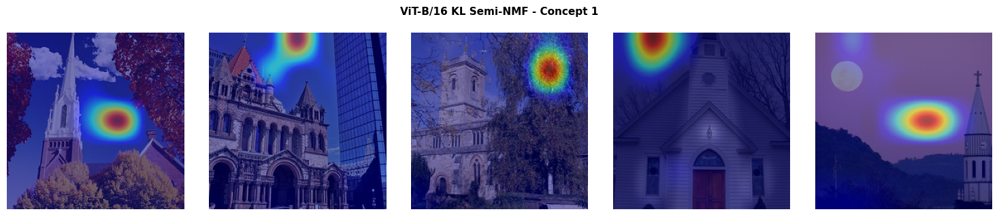

  Saved: ./output/vit_kl_concept02.png


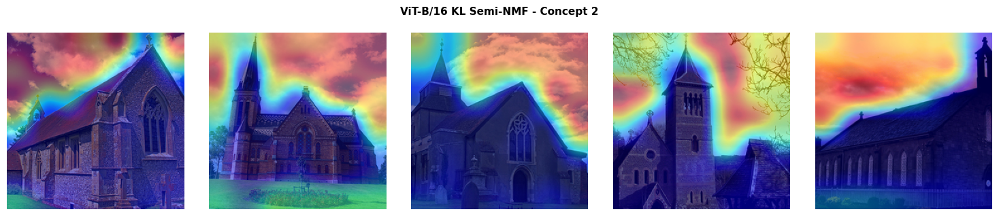

  Saved: ./output/vit_kl_concept04.png


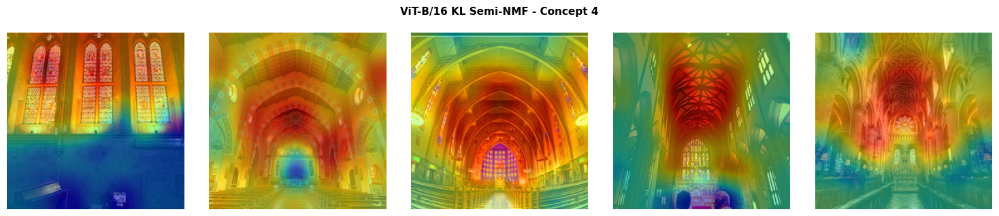

  Saved: ./output/vit_kl_concept03.png


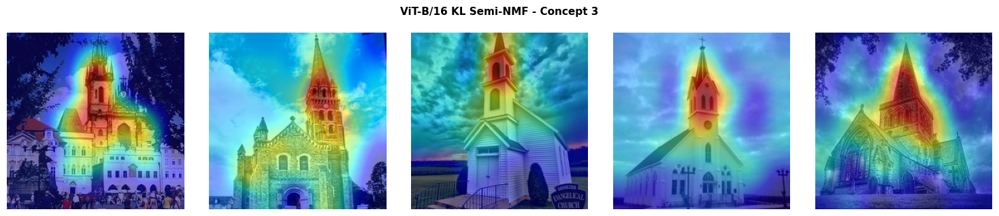

  Saved: ./output/vit_kl_concept05.png


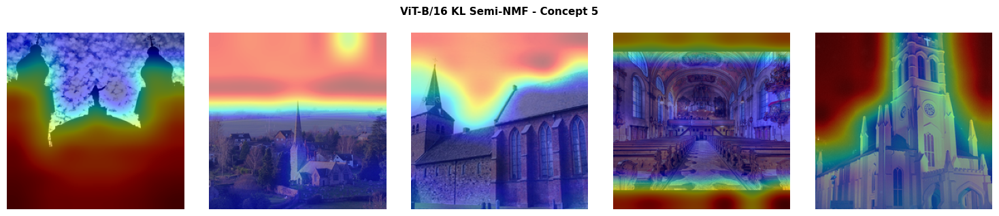

  Saved: ./output/vit_kl_concept06.png


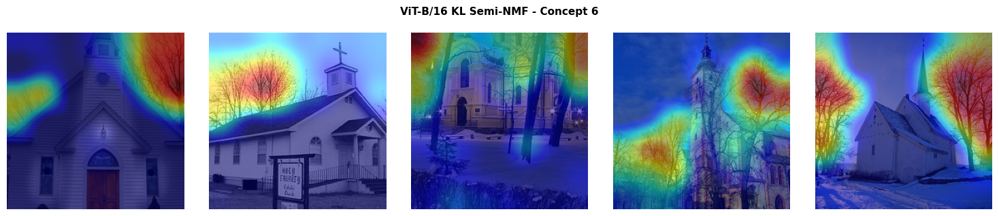

  Saved: ./output/vit_kl_concept08.png


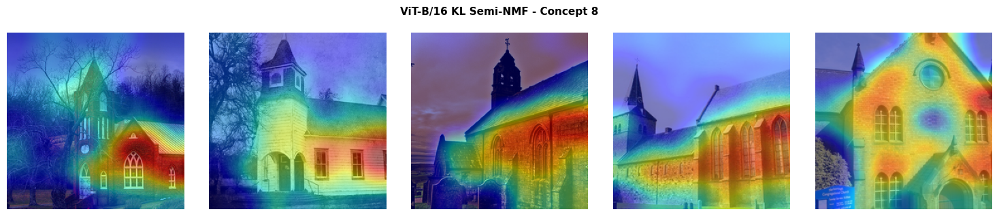

  Saved: ./output/vit_kl_concept11.png


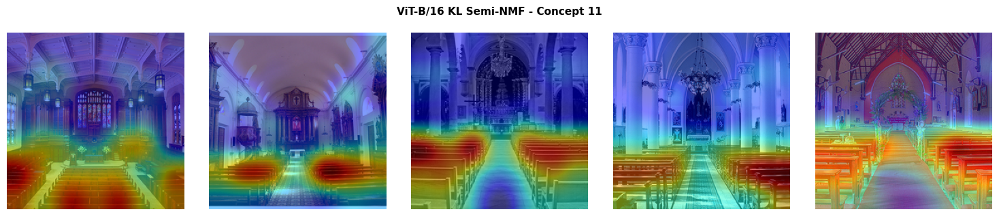

  Saved: ./output/vit_kl_concept07.png


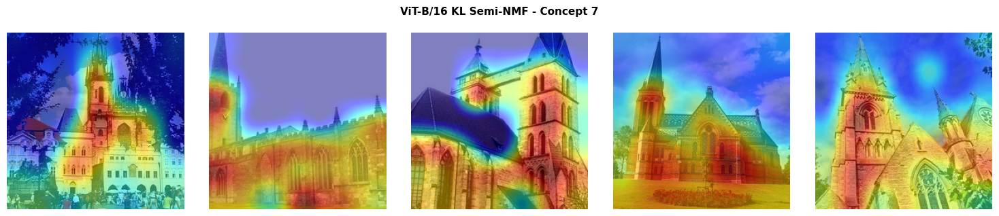

  Saved: ./output/vit_kl_concept09.png


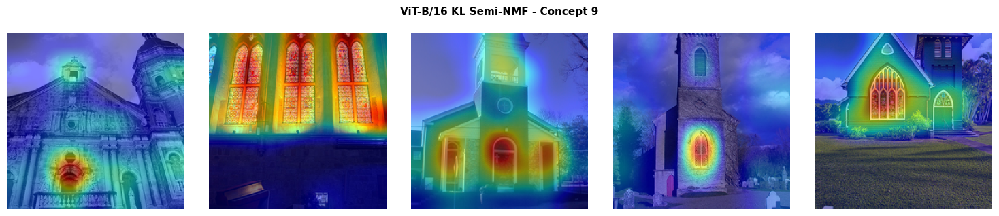

  Saved: ./output/vit_kl_concept10.png


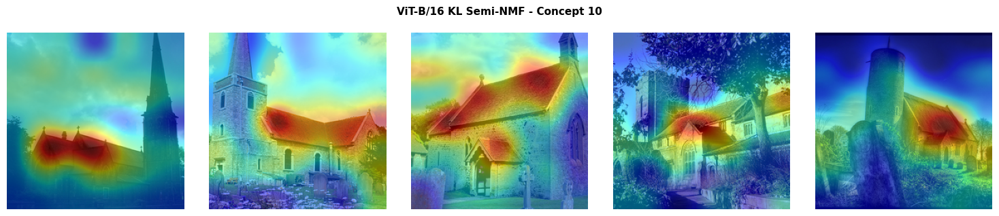

  Saved: ./output/vit_kl_concept12.png


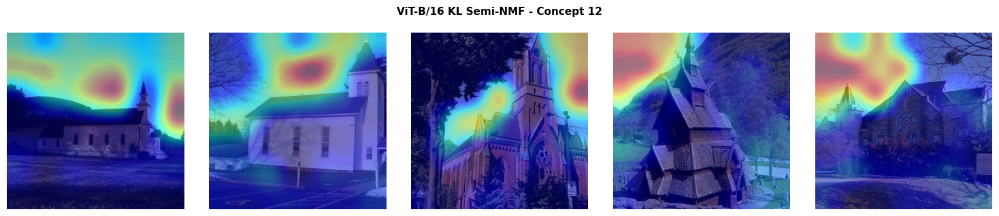

  Saved: ./output/vit_kl_concept13.png


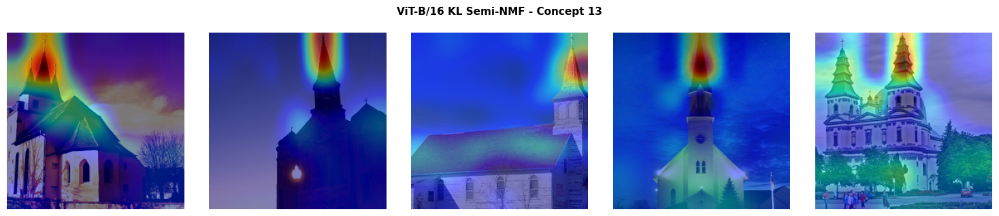

  Saved: ./output/vit_kl_concept14.png


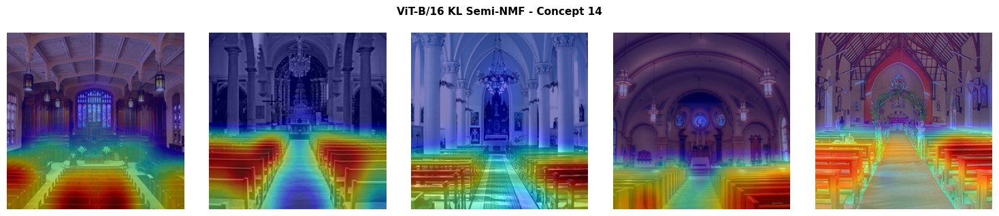

  Saved: ./output/vit_kl_concept15.png


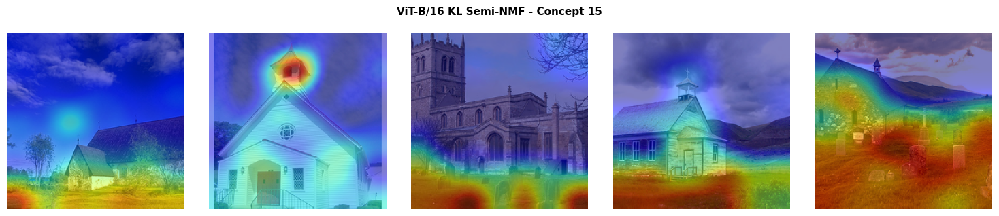

  Saved: ./output/vit_kl_concept18.png


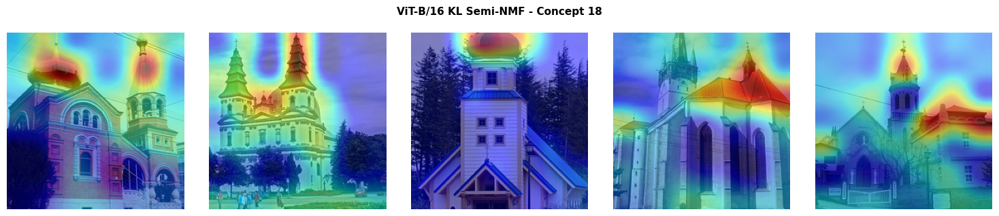

  Saved: ./output/vit_kl_concept20.png


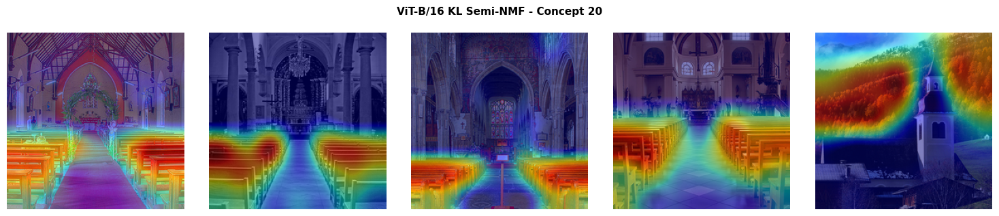

  Saved: ./output/vit_kl_concept16.png


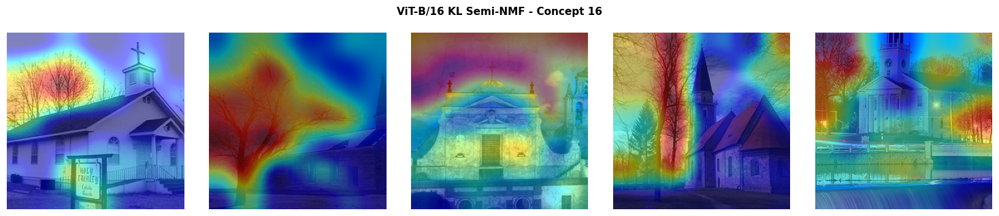

  Saved: ./output/vit_kl_concept19.png


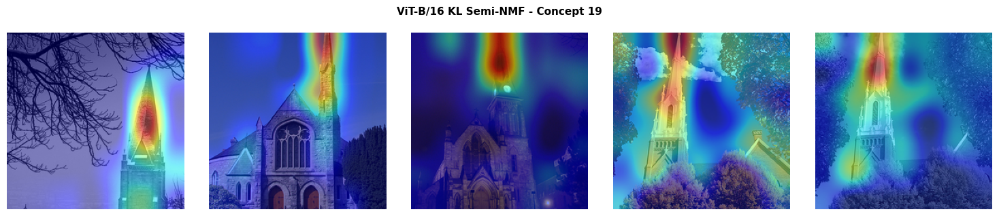

  Saved: ./output/vit_kl_concept22.png


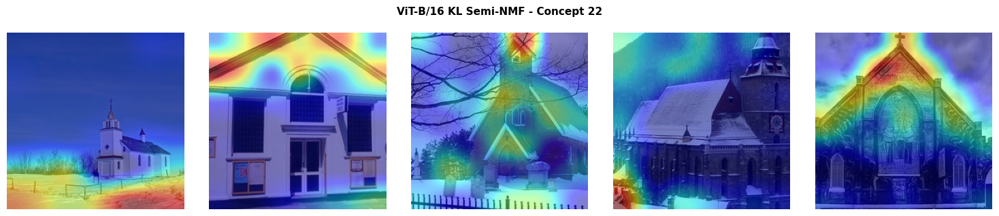

  Saved: ./output/vit_kl_concept21.png


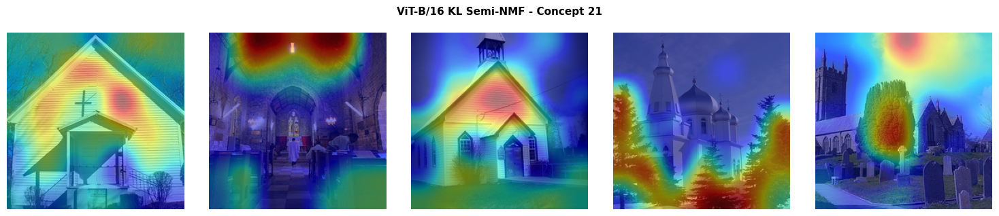

  Saved: ./output/vit_kl_concept17.png


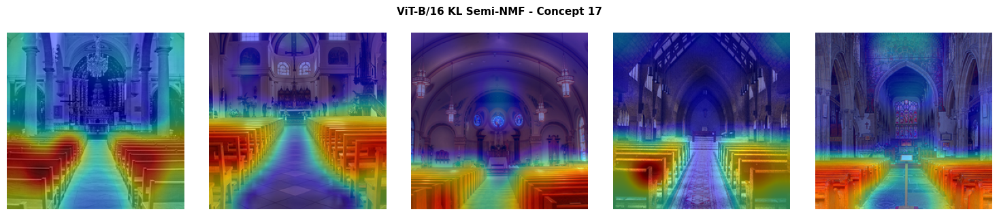

  Saved: ./output/vit_kl_concept23.png


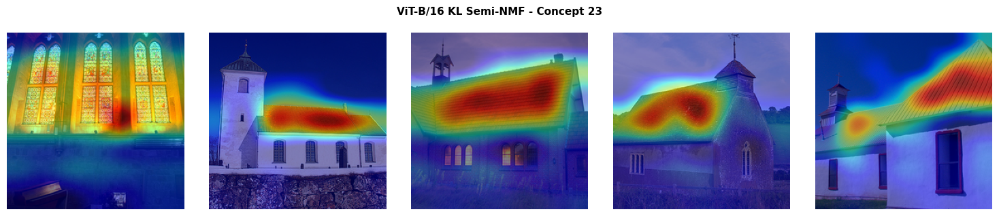

  Saved: ./output/vit_kl_concept24.png


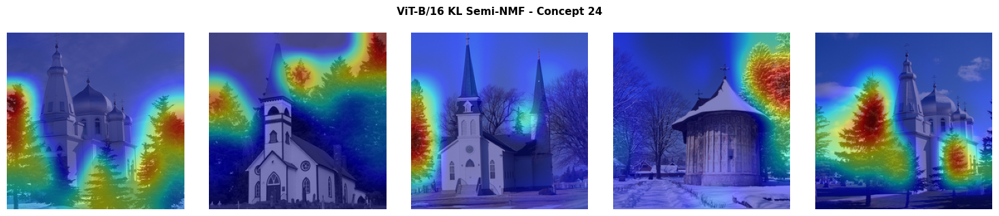

  Saved: ./output/vit_kl_concept00.png


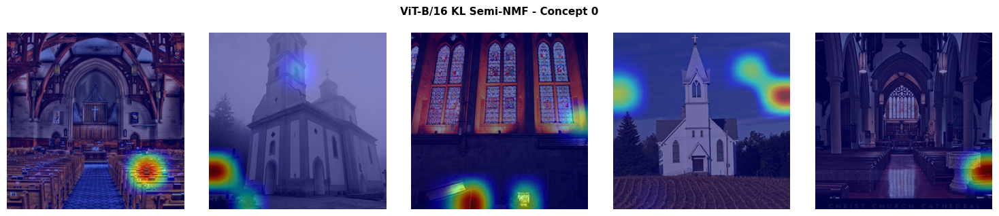

In [12]:
show_concept_heatmaps(
    images_pre_np, U_kl.cpu().numpy(),
    n_per_image=splitter.n_patches_grouped,
    grid_size=splitter.grouped_grid_size,
    n_concepts=RANK, top_k=TOP_K,
    title='ViT-B/16 KL Semi-NMF',
    save_path=f'{OUT_DIR}/vit_kl',
)

### 1b. PLACE (+Gram)

Same tokens and settings, with the KL term replaced by the Gram alignment term
$\|AA^\top - \hat A\hat A^\top\|_F^2 / \|AA^\top\|_F^2$. The classifier is not used during the
optimization (only for the image filtering above).

In [13]:
nmf_gram = PatchNMF(
    model=splitter, rank=RANK, steps=STEPS, learning_rate=LR,
    lambda_val=LAMBDA_VAL, epsilon=EPSILON, batch_size=NMF_BATCH,
    device=DEVICE, use_kl=False, use_gram=True, gram_lambda=LAMBDA_VAL,
    nmf_type='Semi-NMF', target_class=TARGET_CLASS,
    l1_u=L1_U, l2_w=L2_W, nndsvd=NNDSVD,
)

U_gram, W_gram, losses_gram = nmf_gram.fit(cls_sup, patch_tokens_sup)
print(f'Final MSE: {losses_gram["mse"][-1]:.6f} | Gram: {losses_gram["gram"][-1]:.6f}')

imp_gram = nmf_gram.estimate_importance(cls_sup, patch_tokens_sup, U_gram, W_gram, TARGET_CLASS)
gini_gram = compute_gini_index(torch.tensor(imp_gram, dtype=torch.float32))
print(f'C-Gini sparsity: {gini_gram:.4f}')

Initializing Semi-NMF...
  Subsampling 34417/43022 rows for NNDSVD init (80.0%)...


Semi-NMF [MSE+Gram]:   3%|█████████                                                                                                                                                                                                                                                                     | 734/22000 [00:06<03:06, 113.90it/s]

Final MSE: 0.331997 | Gram: 0.011451
C-Gini sparsity: 0.5663


  Saved: ./output/vit_gram_concept01.png


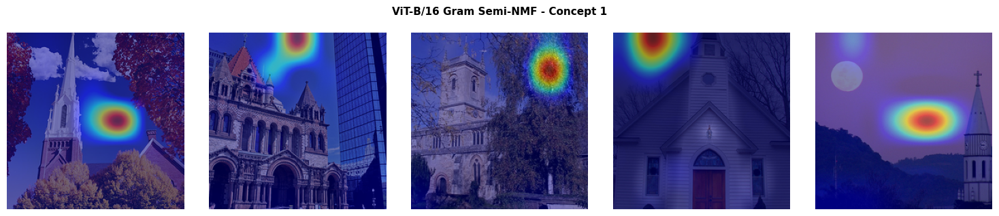

  Saved: ./output/vit_gram_concept02.png


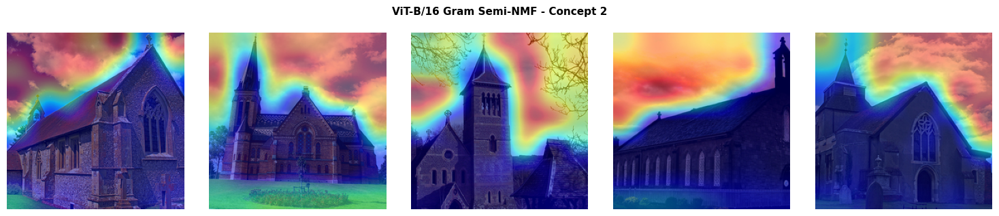

  Saved: ./output/vit_gram_concept04.png


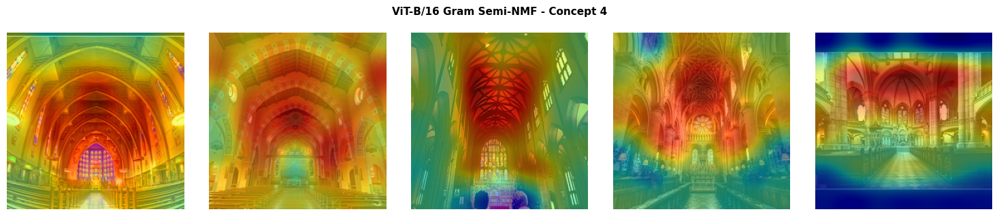

  Saved: ./output/vit_gram_concept06.png


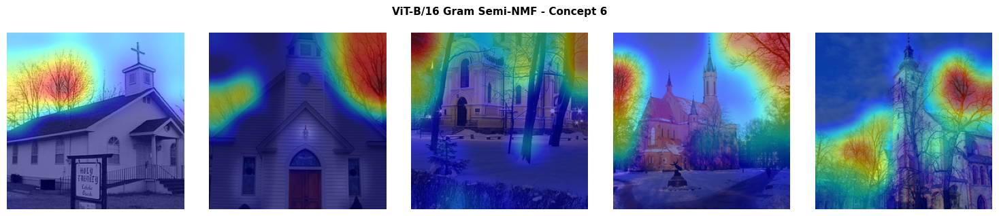

  Saved: ./output/vit_gram_concept03.png


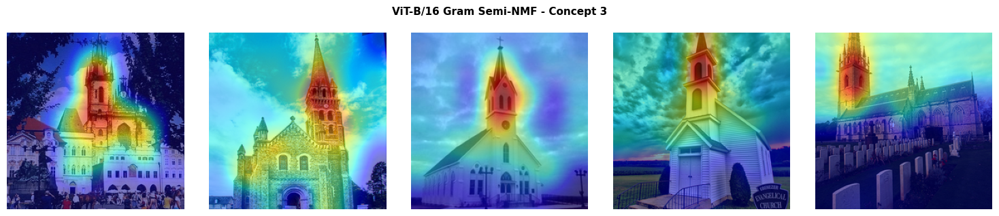

  Saved: ./output/vit_gram_concept05.png


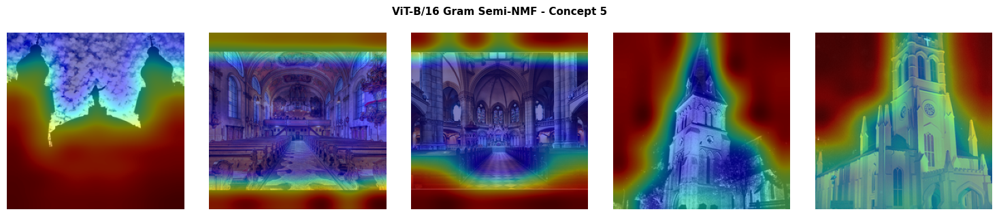

  Saved: ./output/vit_gram_concept11.png


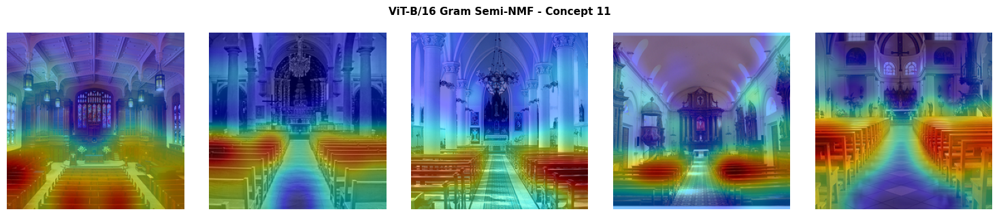

  Saved: ./output/vit_gram_concept08.png


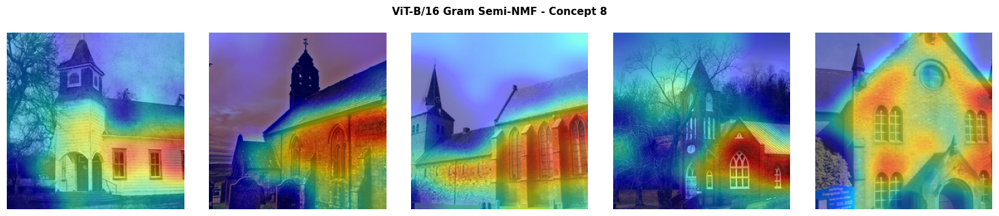

  Saved: ./output/vit_gram_concept09.png


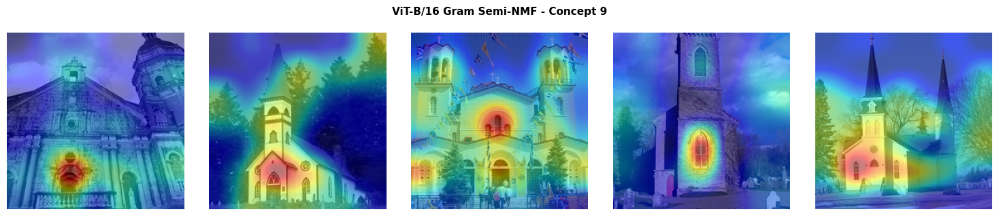

  Saved: ./output/vit_gram_concept10.png


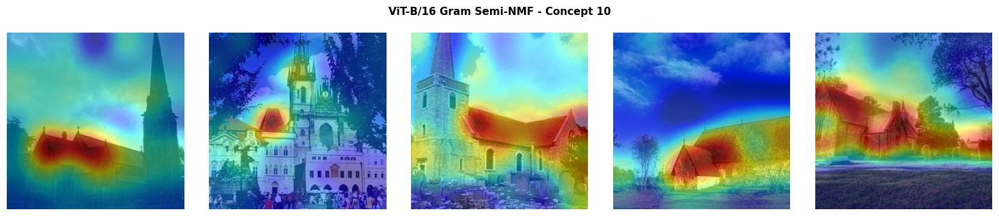

  Saved: ./output/vit_gram_concept07.png


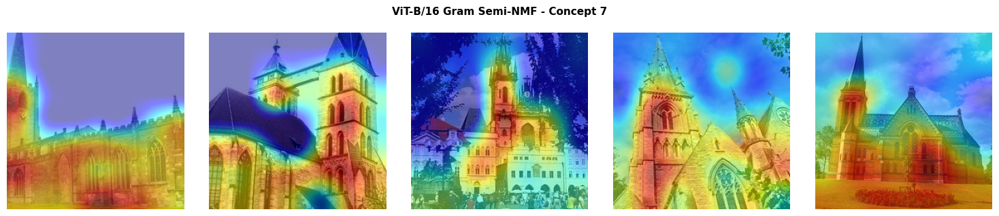

  Saved: ./output/vit_gram_concept12.png


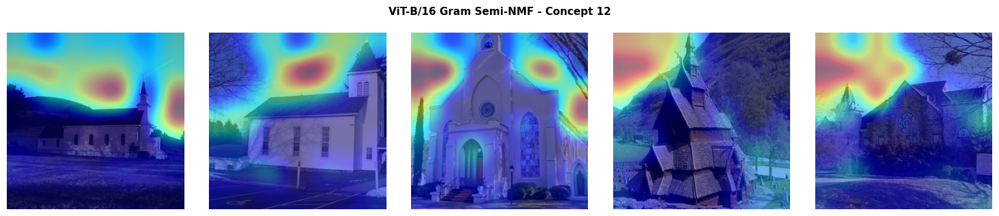

  Saved: ./output/vit_gram_concept15.png


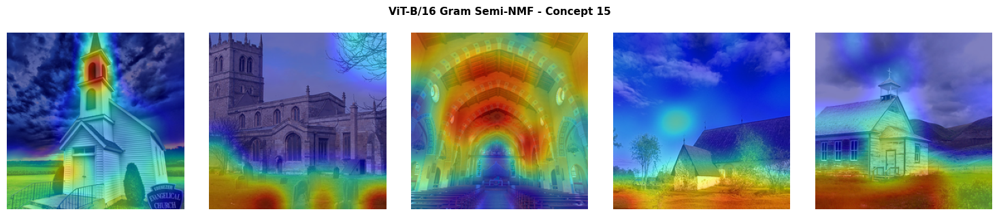

  Saved: ./output/vit_gram_concept19.png


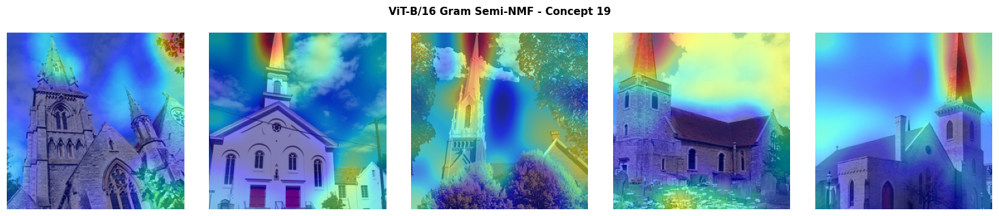

  Saved: ./output/vit_gram_concept13.png


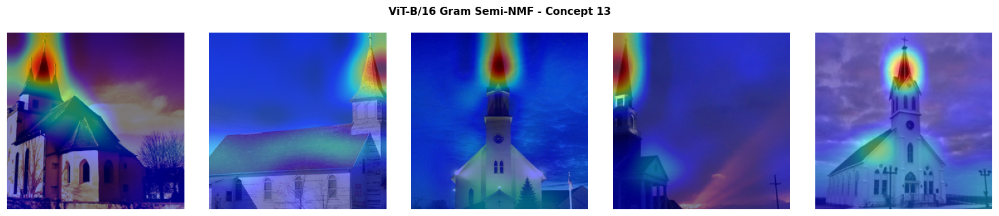

  Saved: ./output/vit_gram_concept21.png


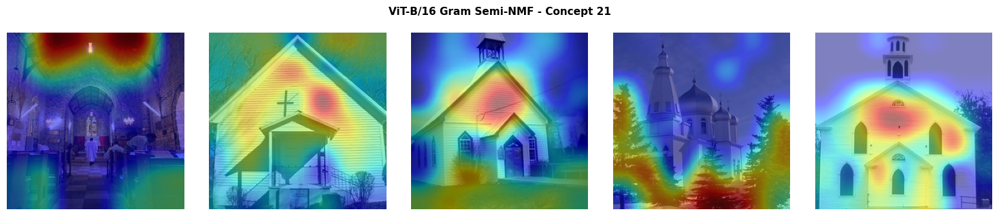

  Saved: ./output/vit_gram_concept22.png


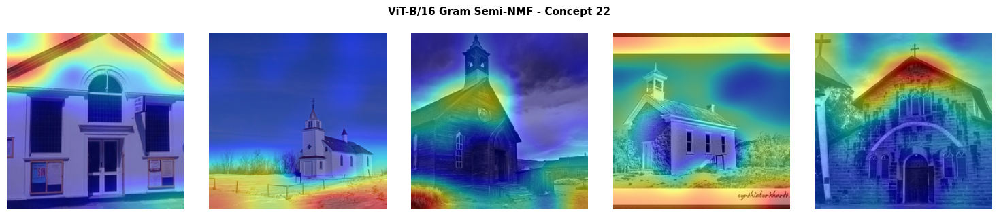

  Saved: ./output/vit_gram_concept14.png


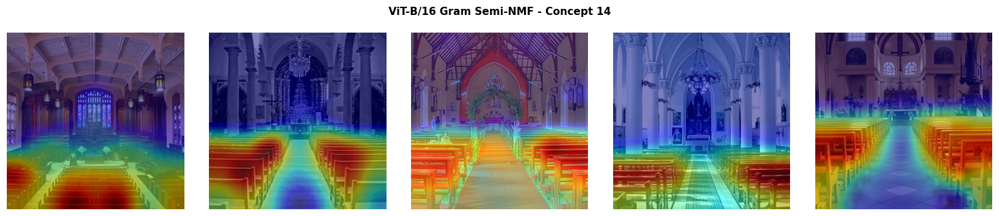

  Saved: ./output/vit_gram_concept20.png


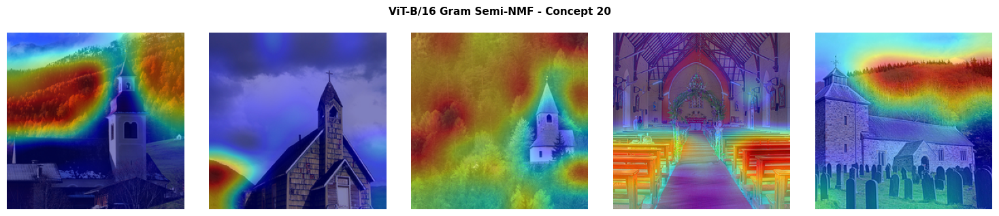

  Saved: ./output/vit_gram_concept18.png


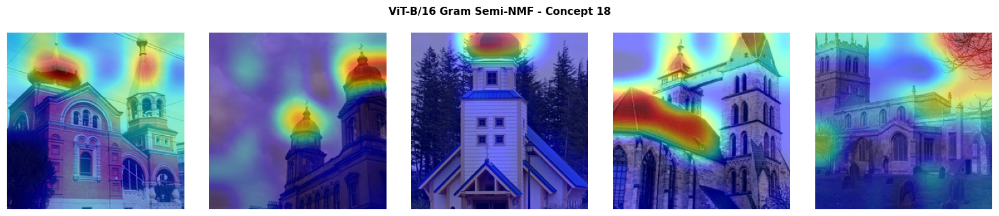

  Saved: ./output/vit_gram_concept16.png


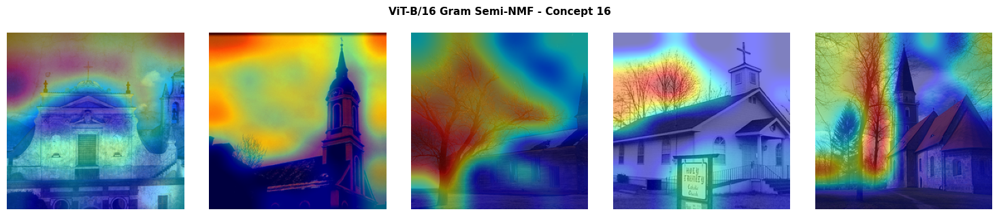

  Saved: ./output/vit_gram_concept23.png


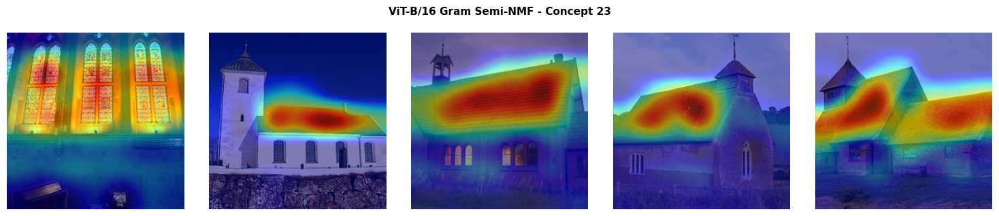

  Saved: ./output/vit_gram_concept24.png


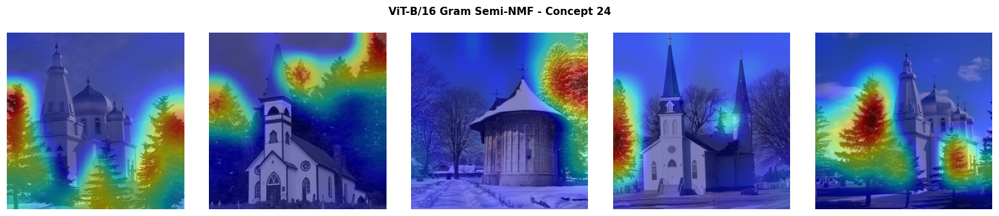

  Saved: ./output/vit_gram_concept17.png


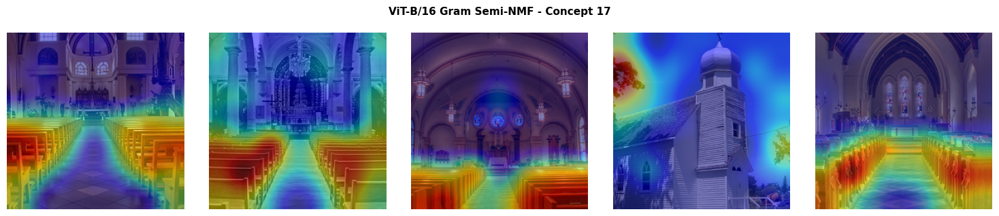

  Saved: ./output/vit_gram_concept00.png


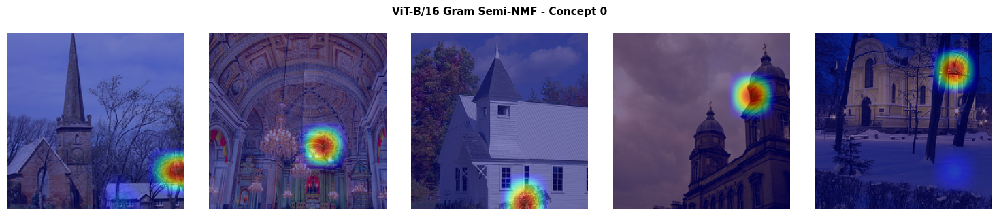

In [14]:
show_concept_heatmaps(
    images_pre_np, U_gram.cpu().numpy(),
    n_per_image=splitter.n_patches_grouped,
    grid_size=splitter.grouped_grid_size,
    n_concepts=RANK, top_k=TOP_K,
    title='ViT-B/16 Gram Semi-NMF',
    save_path=f'{OUT_DIR}/vit_gram',
)

---

## 2. DINOv2 ViT-S/14

Self-supervised backbone without a classifier: no labels and no filtering. Patch tokens after block
9 for the first `VFM_N_IMAGES` images. With 14-pixel patches, a 224×224 image gives a 16×16 grid,
i.e. 64 tokens per image after grouping (dimension 384). The paper uses ViT-B/14; ViT-S/14 is used
here to keep the demo light.


=== 2. Unsupervised DINOv2 ViT-S/14 + Gram Semi-NMF ===
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to ~/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to ~/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 84.2M/84.2M [00:00<00:00, 105MB/s]


  patch_px=14 | group_size=2 | 64 tokens/image | hidden=384


Extracting patch tokens: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 15.02it/s]


  Patch tokens: torch.Size([200, 64, 384])
Initializing Semi-NMF...
  Subsampling 10240/12800 rows for NNDSVD init (80.0%)...


Semi-NMF [MSE+Gram]:   4%|████████████▏                                                                                                                                                                                                                                                                 | 988/22000 [00:02<00:53, 394.89it/s]


  Final MSE: 0.014513 | Gram: 0.012174
  C-Gini sparsity: 0.4232
  Saved: ./output/dinov2_gram_concept01.png


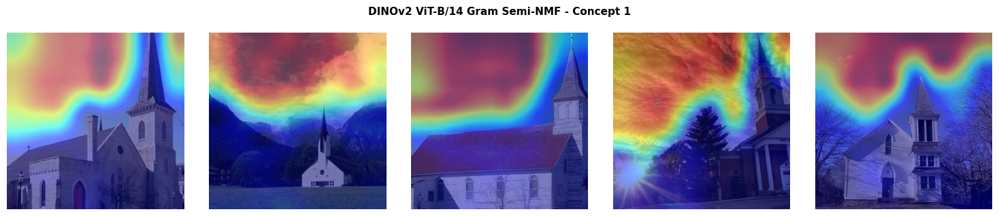

  Saved: ./output/dinov2_gram_concept03.png


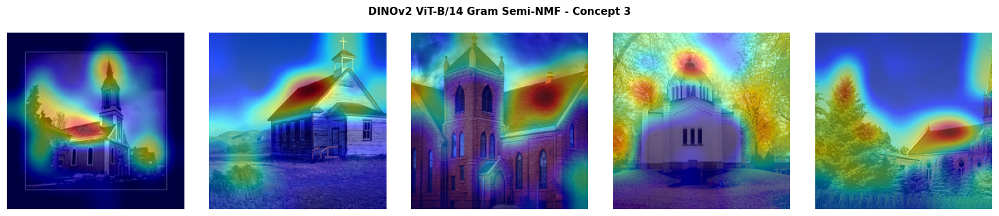

  Saved: ./output/dinov2_gram_concept05.png


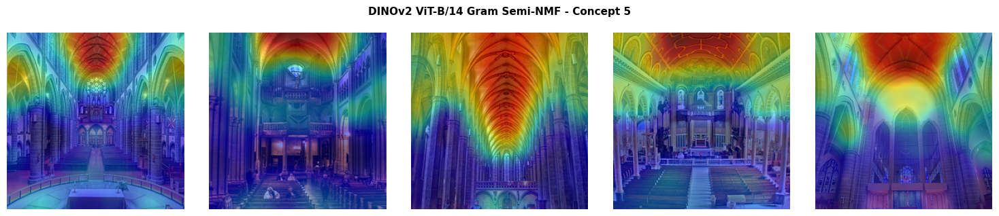

  Saved: ./output/dinov2_gram_concept02.png


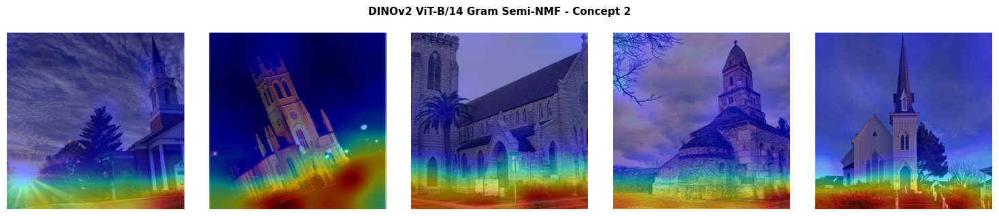

  Saved: ./output/dinov2_gram_concept04.png


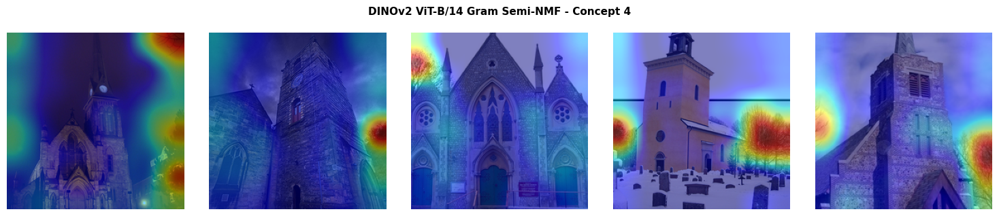

  Saved: ./output/dinov2_gram_concept08.png


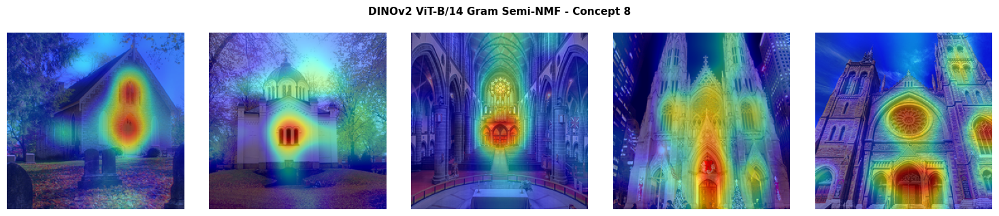

  Saved: ./output/dinov2_gram_concept06.png


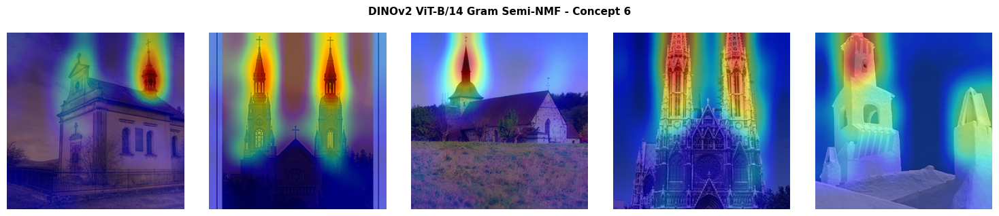

  Saved: ./output/dinov2_gram_concept10.png


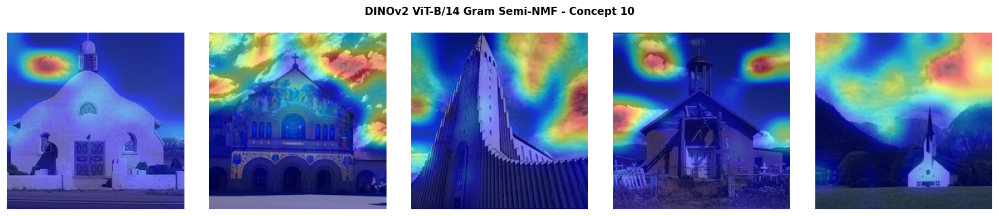

  Saved: ./output/dinov2_gram_concept07.png


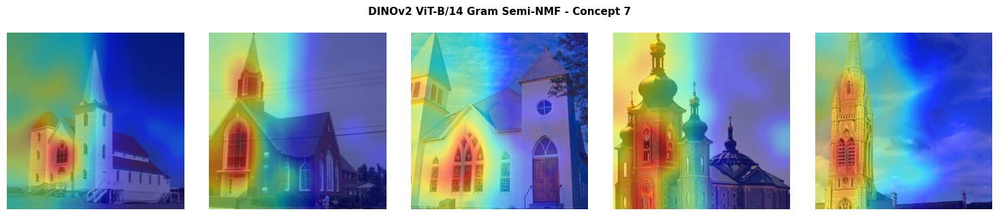

  Saved: ./output/dinov2_gram_concept11.png


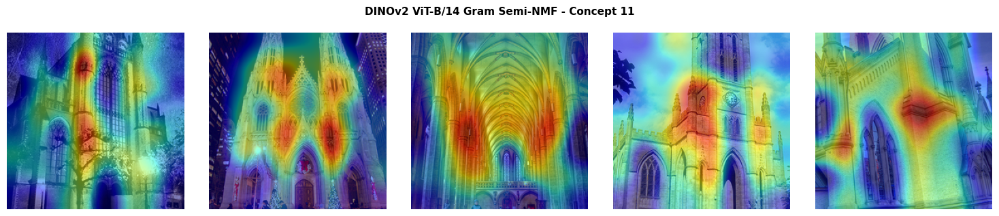

  Saved: ./output/dinov2_gram_concept12.png


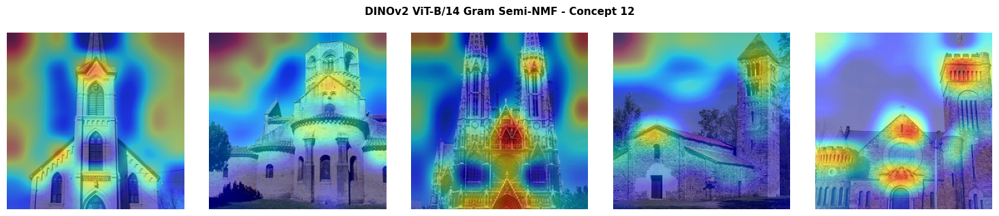

  Saved: ./output/dinov2_gram_concept09.png


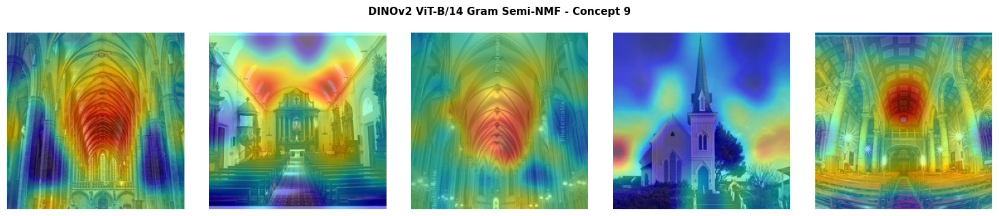

  Saved: ./output/dinov2_gram_concept15.png


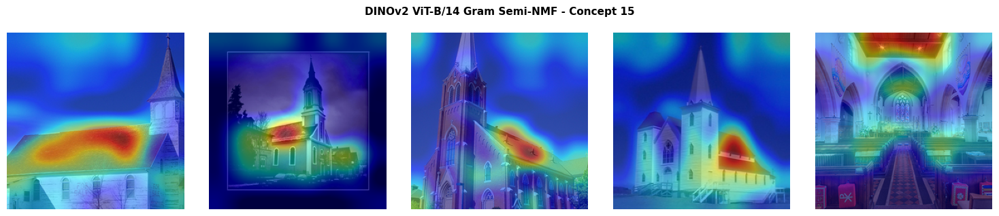

  Saved: ./output/dinov2_gram_concept00.png


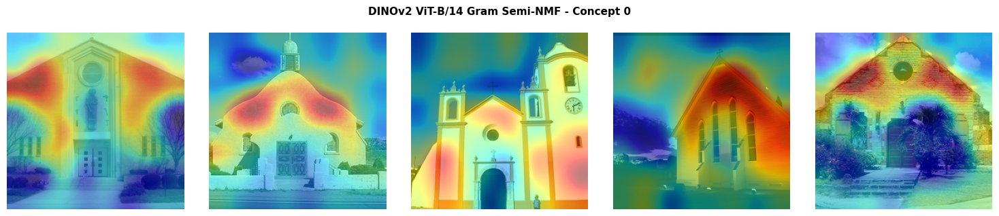

  Saved: ./output/dinov2_gram_concept13.png


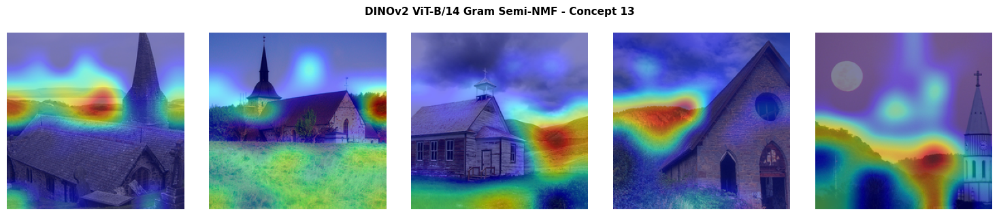

  Saved: ./output/dinov2_gram_concept16.png


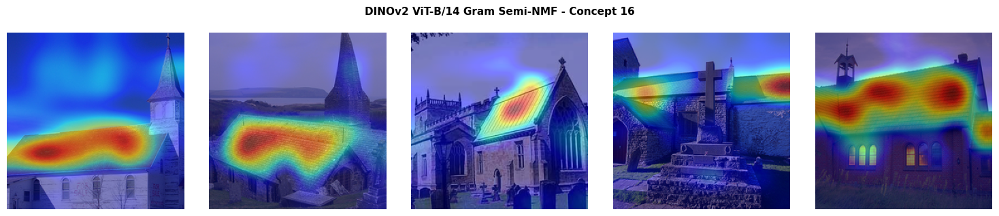

  Saved: ./output/dinov2_gram_concept14.png


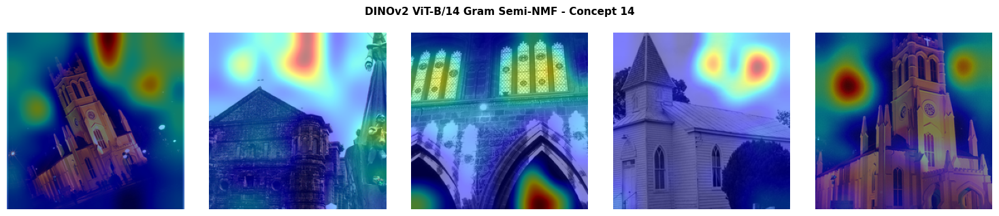

  Saved: ./output/dinov2_gram_concept19.png


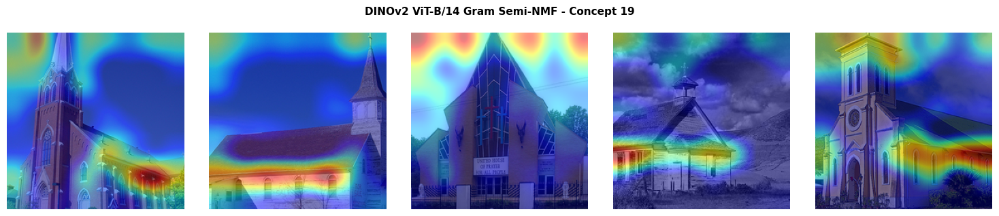

  Saved: ./output/dinov2_gram_concept18.png


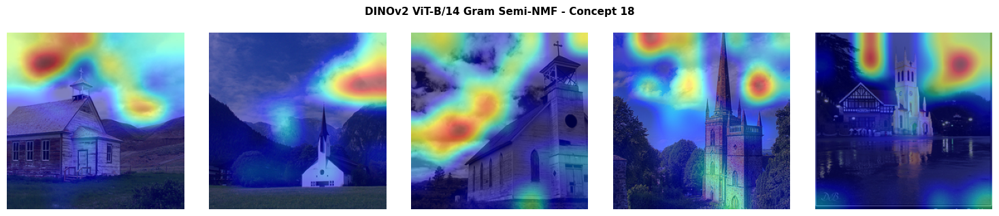

  Saved: ./output/dinov2_gram_concept21.png


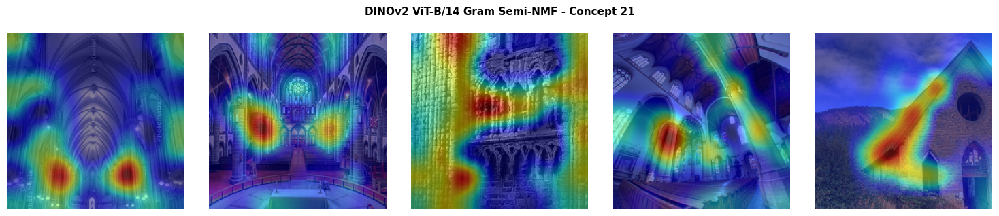

  Saved: ./output/dinov2_gram_concept17.png


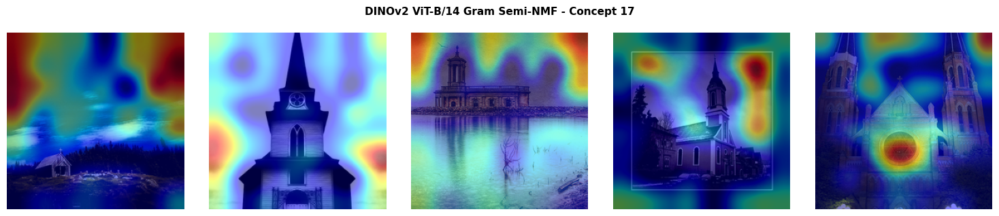

  Saved: ./output/dinov2_gram_concept24.png


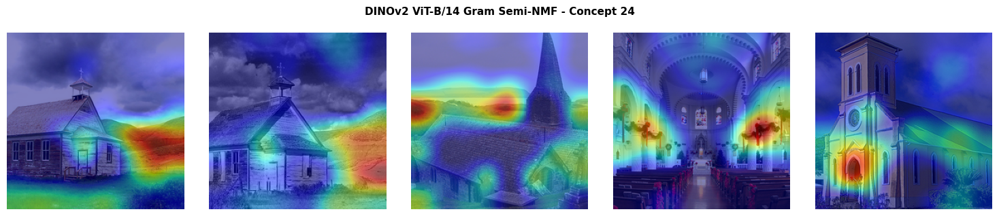

  Saved: ./output/dinov2_gram_concept23.png


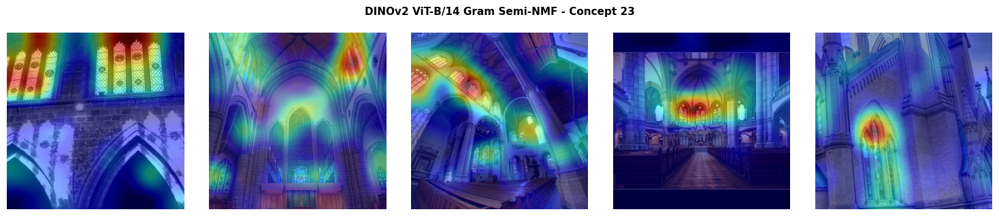

  Saved: ./output/dinov2_gram_concept22.png


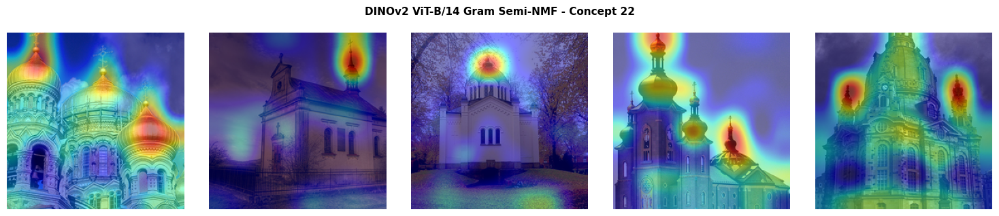

  Saved: ./output/dinov2_gram_concept20.png


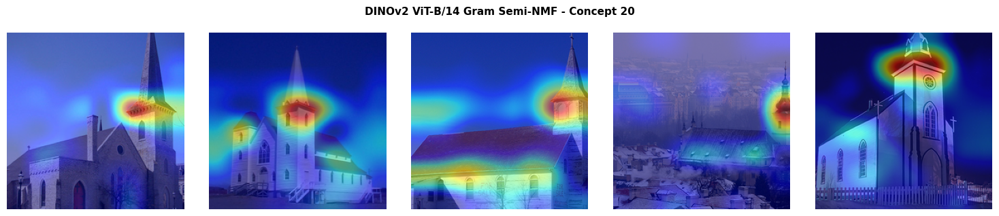

In [15]:
# ── 2. Unsupervised: DINOv2 ViT-S/14 + Gram Semi-NMF ────────────────────
print('\n=== 2. Unsupervised DINOv2 ViT-S/14 + Gram Semi-NMF ===')
dino_raw = load_vfm('dinov2', 'dinov2_vits14')
dino_ext = VFMFeatureExtractor(
    dino_raw, extract_layer=VFM_LAYER, group_size=GROUP_SIZE
).to(DEVICE)
print(f'  patch_px={dino_ext.patch_pixel_size} | group_size={dino_ext.group_size} | '
      f'{dino_ext.n_patches_grouped} tokens/image | hidden={dino_ext.hidden_dim}')

nmf_dino = UnsupervisedPatchNMF(
    model=dino_ext, rank=RANK, steps=STEPS, learning_rate=LR,
    lambda_val=LAMBDA_VAL, epsilon=EPSILON, batch_size=BATCH_SIZE,
    device=DEVICE, nmf_type='Semi-NMF',
    use_gram=True, gram_lambda=LAMBDA_VAL,
    l1_u=L1_U, l2_w=L2_W, nndsvd=NNDSVD,
)

imgs_dino = nmf_dino.preprocess_images(images_np[:VFM_N_IMAGES])
tokens_dino = nmf_dino.extract_all(imgs_dino)
print(f'  Patch tokens: {tokens_dino.shape}')

U_dino, W_dino, losses_dino = nmf_dino.fit(tokens_dino)
print(f'  Final MSE: {losses_dino["mse"][-1]:.6f} | Gram: {losses_dino["gram"][-1]:.6f}')
imp_dino = nmf_dino.estimate_importance(U_dino, W_dino)
gini_dino = compute_gini_index(torch.tensor(imp_dino, dtype=torch.float32))
print(f'  C-Gini sparsity: {gini_dino:.4f}')

show_concept_heatmaps(
    imgs_dino.cpu().numpy(), U_dino.cpu().numpy(),
    n_per_image=dino_ext.n_patches_grouped,
    grid_size=dino_ext.grouped_grid_size,
    n_concepts=RANK, top_k=TOP_K,
    title='DINOv2 ViT-S/14 Gram Semi-NMF',
    save_path=f'{OUT_DIR}/dinov2_gram',
)

---

## 3. ViT-MAE ViT-B/16

Same procedure with a ViT-B/16 pretrained as a masked autoencoder (timm
`vit_base_patch16_224.mae`): 16-pixel patches, 49 tokens of dimension 768 per image.


=== 3. Unsupervised ViT-MAE ViT-B/16 + Gram Semi-NMF ===


  patch_px=16 | group_size=2 | 49 tokens/image | hidden=768


Extracting patch tokens: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00,  6.53it/s]


  Patch tokens: torch.Size([200, 49, 768])
Initializing Semi-NMF...
  Subsampling 7840/9800 rows for NNDSVD init (80.0%)...


Semi-NMF [MSE+Gram]:   2%|██████▌                                                                                                                                                                                                                                                                       | 530/22000 [00:02<01:29, 239.68it/s]


  Final MSE: 0.851246 | Gram: 0.004043
  C-Gini sparsity: 0.5111
  Saved: ./output/mae_gram_concept04.png


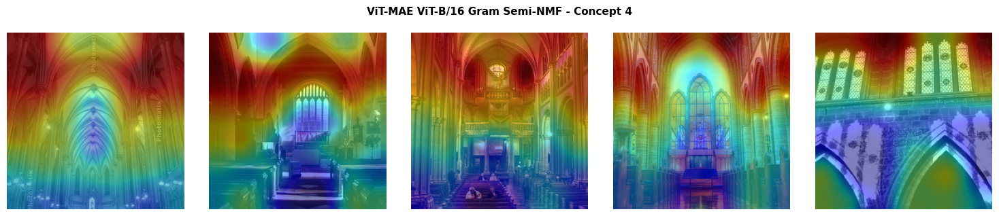

  Saved: ./output/mae_gram_concept19.png


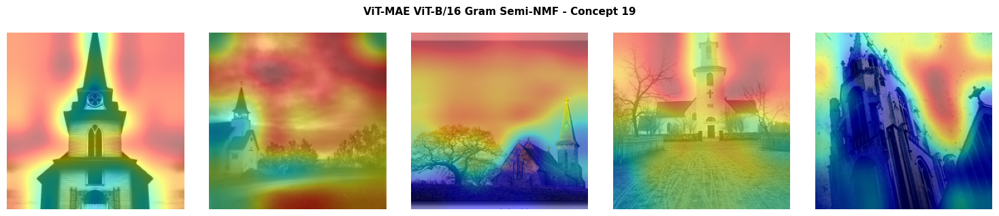

  Saved: ./output/mae_gram_concept08.png


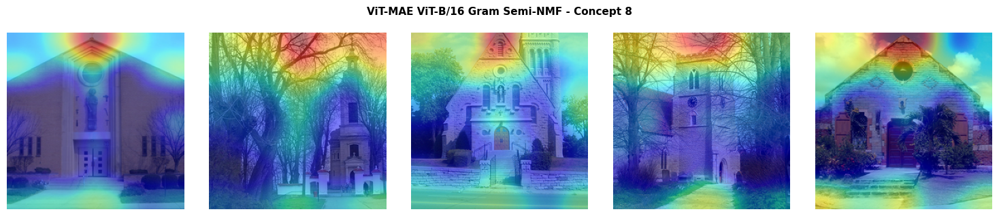

  Saved: ./output/mae_gram_concept06.png


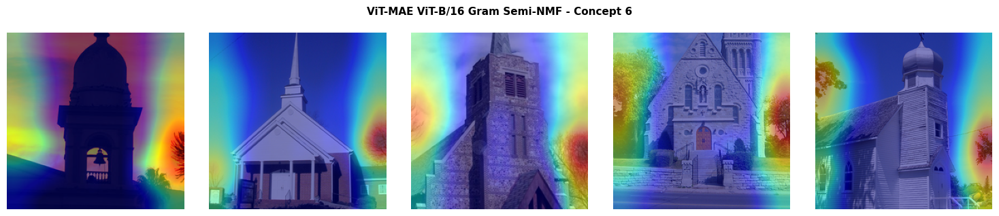

  Saved: ./output/mae_gram_concept05.png


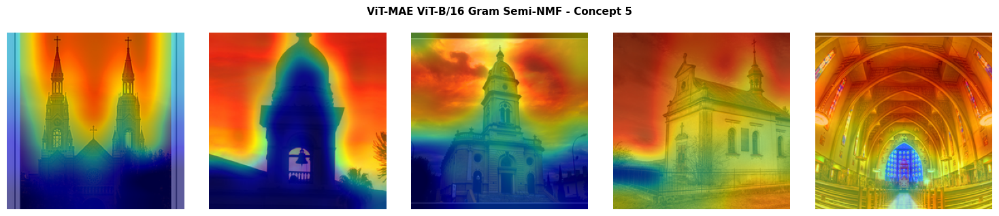

  Saved: ./output/mae_gram_concept02.png


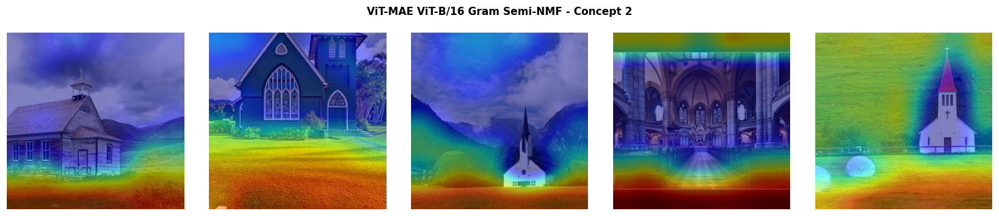

  Saved: ./output/mae_gram_concept15.png


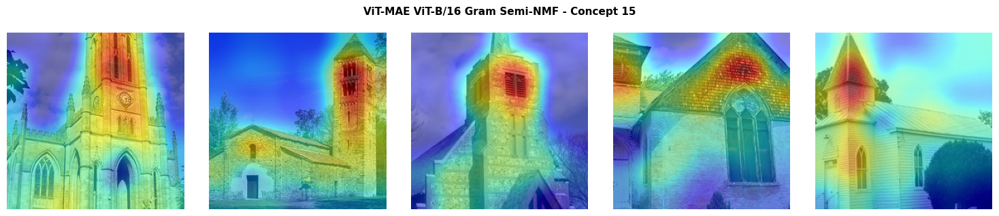

  Saved: ./output/mae_gram_concept24.png


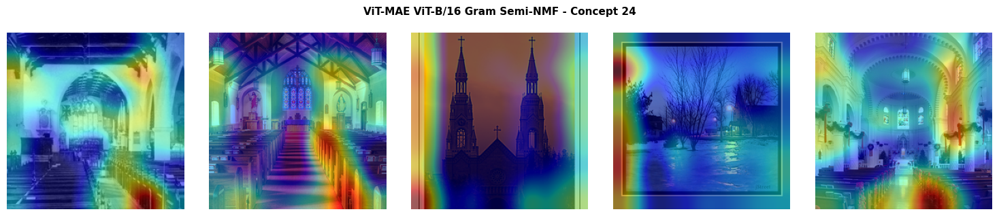

  Saved: ./output/mae_gram_concept14.png


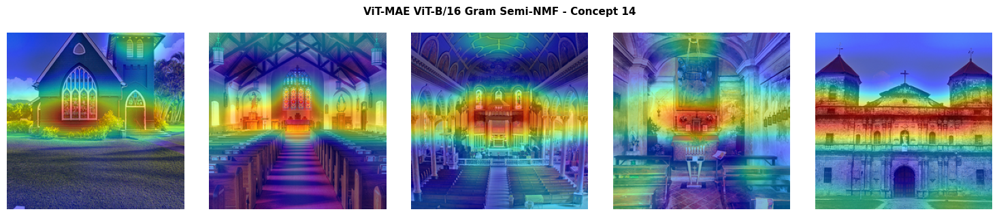

  Saved: ./output/mae_gram_concept22.png


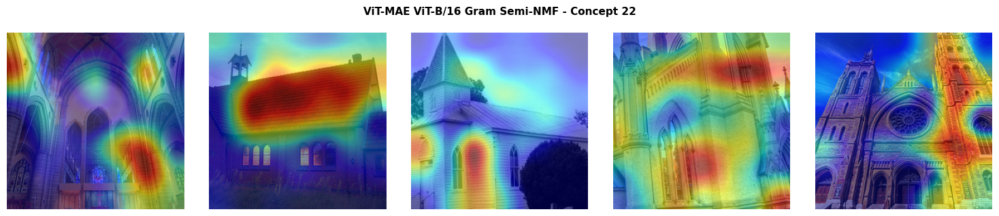

  Saved: ./output/mae_gram_concept11.png


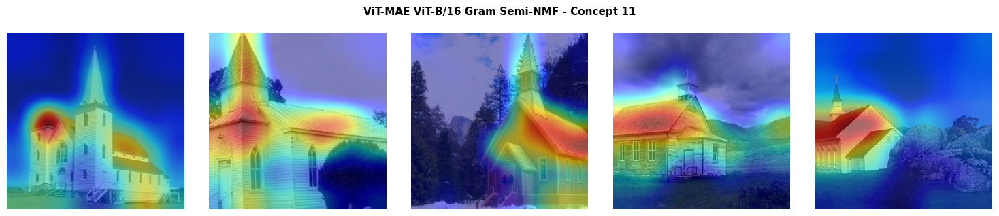

  Saved: ./output/mae_gram_concept13.png


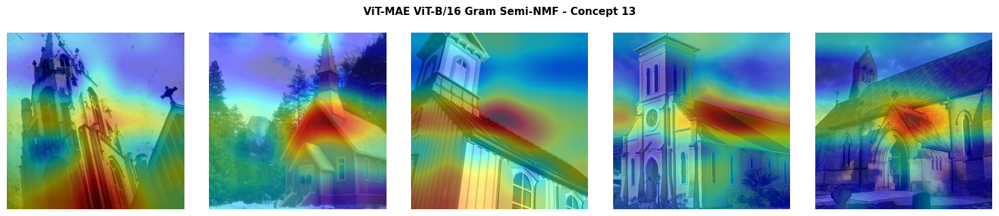

  Saved: ./output/mae_gram_concept03.png


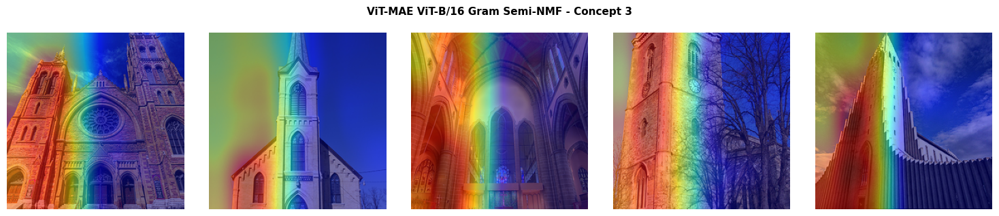

  Saved: ./output/mae_gram_concept00.png


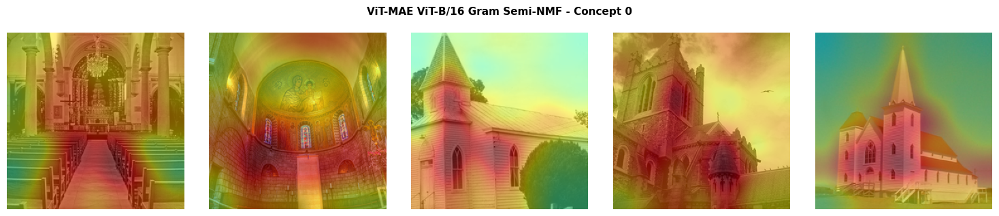

  Saved: ./output/mae_gram_concept09.png


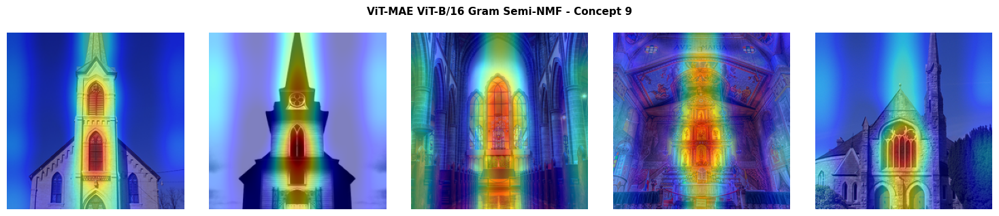

  Saved: ./output/mae_gram_concept20.png


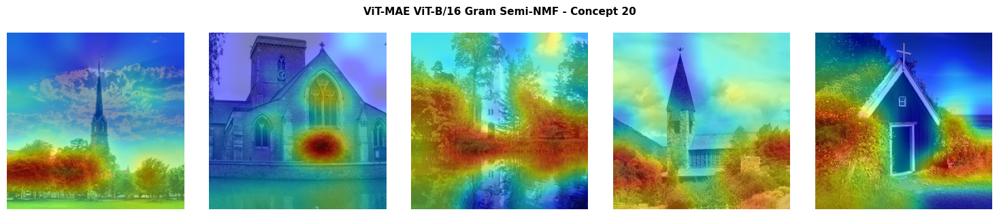

  Saved: ./output/mae_gram_concept10.png


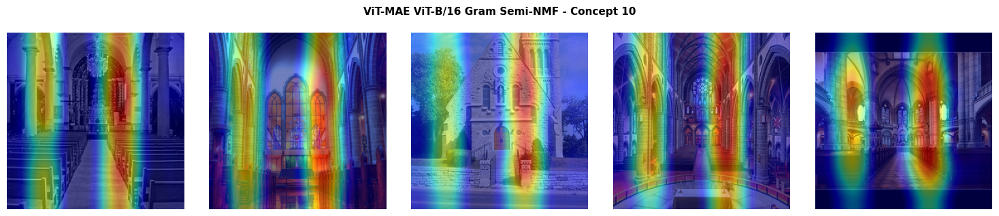

  Saved: ./output/mae_gram_concept16.png


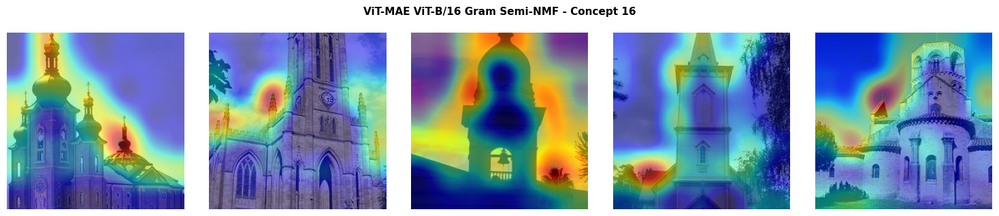

  Saved: ./output/mae_gram_concept07.png


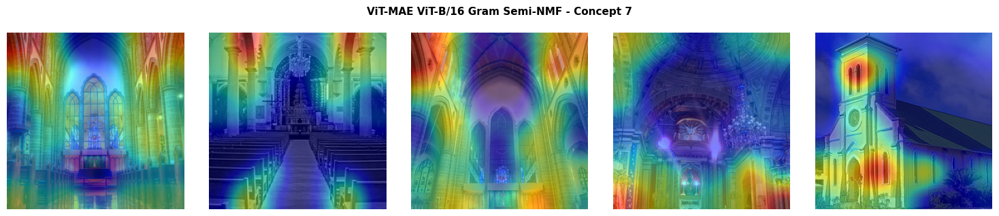

  Saved: ./output/mae_gram_concept12.png


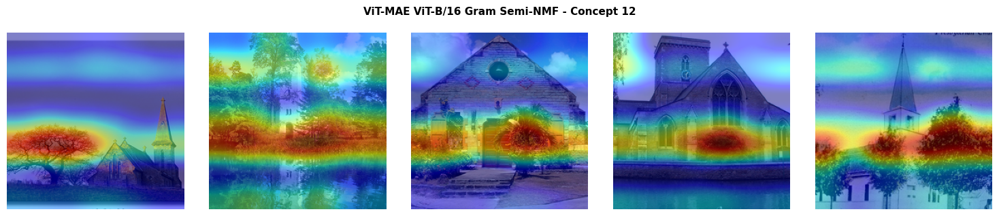

  Saved: ./output/mae_gram_concept18.png


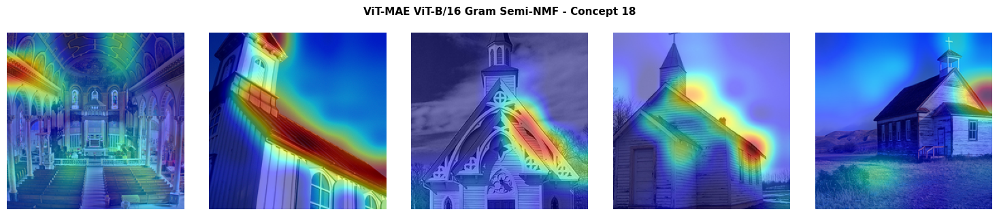

  Saved: ./output/mae_gram_concept17.png


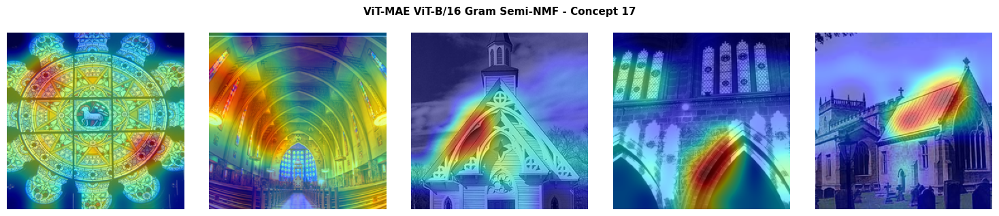

  Saved: ./output/mae_gram_concept21.png


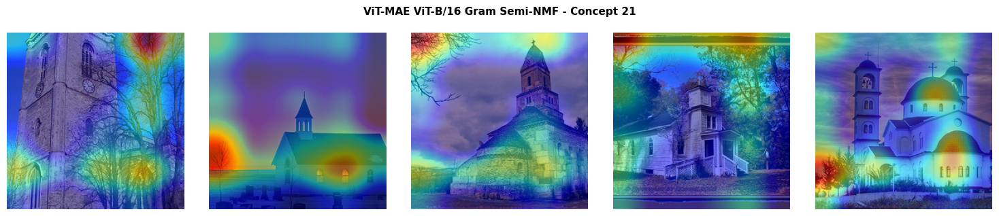

  Saved: ./output/mae_gram_concept01.png


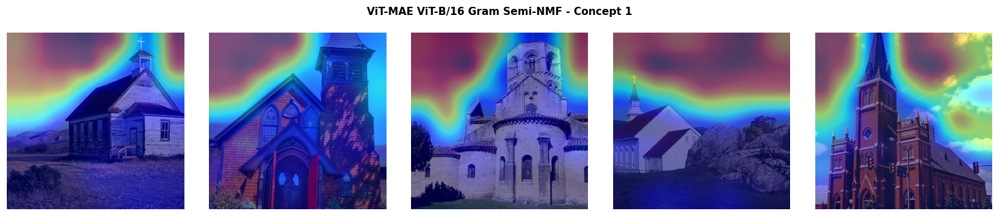

  Saved: ./output/mae_gram_concept23.png


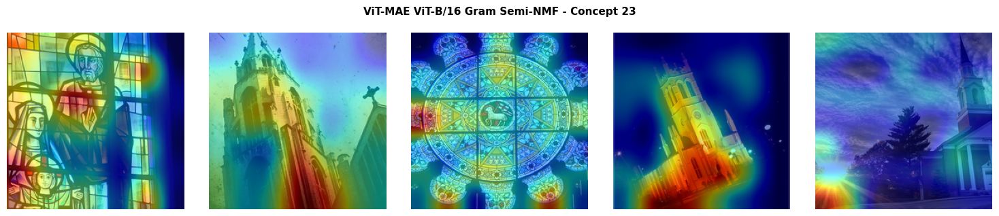

In [16]:
# ── 3. Unsupervised: ViT-MAE + Gram Semi-NMF ─────────────────────────────
print('\n=== 3. Unsupervised ViT-MAE ViT-B/16 + Gram Semi-NMF ===')
mae_raw = load_vfm('mae', 'vit_base_patch16_224.mae')
mae_ext = VFMFeatureExtractor(
    mae_raw, extract_layer=VFM_LAYER, group_size=GROUP_SIZE
).to(DEVICE)
print(f'  patch_px={mae_ext.patch_pixel_size} | group_size={mae_ext.group_size} | '
      f'{mae_ext.n_patches_grouped} tokens/image | hidden={mae_ext.hidden_dim}')

nmf_mae = UnsupervisedPatchNMF(
    model=mae_ext, rank=RANK, steps=STEPS, learning_rate=LR,
    lambda_val=LAMBDA_VAL, epsilon=EPSILON, batch_size=BATCH_SIZE,
    device=DEVICE, nmf_type='Semi-NMF',
    use_gram=True, gram_lambda=LAMBDA_VAL,
    l1_u=L1_U, l2_w=L2_W, nndsvd=NNDSVD,
)

imgs_mae = nmf_mae.preprocess_images(images_np[:VFM_N_IMAGES])
tokens_mae = nmf_mae.extract_all(imgs_mae)
print(f'  Patch tokens: {tokens_mae.shape}')

U_mae, W_mae, losses_mae = nmf_mae.fit(tokens_mae)
print(f'  Final MSE: {losses_mae["mse"][-1]:.6f} | Gram: {losses_mae["gram"][-1]:.6f}')
imp_mae = nmf_mae.estimate_importance(U_mae, W_mae)
gini_mae = compute_gini_index(torch.tensor(imp_mae, dtype=torch.float32))
print(f'  C-Gini sparsity: {gini_mae:.4f}')

show_concept_heatmaps(
    imgs_mae.cpu().numpy(), U_mae.cpu().numpy(),
    n_per_image=mae_ext.n_patches_grouped,
    grid_size=mae_ext.grouped_grid_size,
    n_concepts=RANK, top_k=TOP_K,
    title='ViT-MAE ViT-B/16 Gram Semi-NMF',
    save_path=f'{OUT_DIR}/mae_gram',
)

---

## Summary

Prints C-Gini for the four runs. With `COMPUTE_STABILITY = True`, each method is refitted five times
with different seeds and W-Stab is reported: concepts of different runs are matched with the
Hungarian algorithm and the cosine similarities of the matched pairs are averaged (1 = identical
concepts).

Saved run: C-Gini 0.55 (+KL), 0.57 (+Gram), 0.42 (DINOv2), 0.51 (MAE); W-Stab between 0.87 and 0.91.
These are single-class, single-seed values with a lighter setup than the paper, so they are not
directly comparable to Table 1. Figures are saved to `output/`.

In [17]:
# ── Summary ──────────────────────────────────────────────────────────────
print('\n' + '='*55)
print(f'  ViT-B/16  KL Semi-NMF    C-Gini = {gini_kl:.4f}')
print(f'  ViT-B/16  Gram Semi-NMF  C-Gini = {gini_gram:.4f}')
print(f'  DINOv2    Gram Semi-NMF  C-Gini = {gini_dino:.4f}')
print(f'  ViT-MAE   Gram Semi-NMF  C-Gini = {gini_mae:.4f}')
print('='*55)

if COMPUTE_STABILITY:
    print('\n=== Stability (5 NMF runs each) ===')
    stab_kl   = nmf_kl.compute_stability(cls_sup, patch_tokens_sup)
    stab_gram = nmf_gram.compute_stability(cls_sup, patch_tokens_sup)
    stab_dino = nmf_dino.compute_stability(tokens_dino)
    stab_mae  = nmf_mae.compute_stability(tokens_mae)
    print(f'  ViT-B/16  KL   stability = {stab_kl:.4f}')
    print(f'  ViT-B/16  Gram stability = {stab_gram:.4f}')
    print(f'  DINOv2    Gram stability = {stab_dino:.4f}')
    print(f'  ViT-MAE   Gram stability = {stab_mae:.4f}')

print(f'\n=== Done. Figures saved to {OUT_DIR}/ ===')


  ViT-B/16  KL Semi-NMF    C-Gini = 0.5502
  ViT-B/16  Gram Semi-NMF  C-Gini = 0.5663
  DINOv2    Gram Semi-NMF  C-Gini = 0.4232
  ViT-MAE   Gram Semi-NMF  C-Gini = 0.5111

=== Stability (5 NMF runs each) ===
Initializing Semi-NMF...
  Subsampling 34417/43022 rows for NNDSVD init (80.0%)...
Precomputing original logits...


Semi-NMF [MSE+KL]:  31%|████████████████████████████████████████████████████████████████████████████████████▎                                                                                                                                                                                           | 6816/22000 [06:56<15:27, 16.38it/s]


Initializing Semi-NMF...
  Subsampling 34417/43022 rows for NNDSVD init (80.0%)...
Precomputing original logits...


Semi-NMF [MSE+KL]:  24%|█████████████████████████████████████████████████████████████████▍                                                                                                                                                                                                              | 5292/22000 [05:17<16:41, 16.68it/s]


Initializing Semi-NMF...
  Subsampling 34417/43022 rows for NNDSVD init (80.0%)...
Precomputing original logits...


Semi-NMF [MSE+KL]:  40%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                                                                                                                                                  | 8850/22000 [08:50<13:07, 16.70it/s]


... (31 outputs left out)

Semi-NMF [MSE+Gram]:   2%|██████▋                                                                                                                                                                                                                                                                       | 548/22000 [00:02<01:26, 246.92it/s]


Initializing Semi-NMF...
  Subsampling 7840/9800 rows for NNDSVD init (80.0%)...


Semi-NMF [MSE+Gram]:   3%|███████                                                                                                                                                                                                                                                                       | 578/22000 [00:02<01:28, 243.31it/s]

  ViT-B/16  KL   stability = 0.9069
  ViT-B/16  Gram stability = 0.8717
  DINOv2    Gram stability = 0.9110
  ViT-MAE   Gram stability = 0.8727

=== Done. Figures saved to ./output/ ===
